In [2]:
# conda activate tf
import numpy as np
import random
import pandas as pd
from matplotlib import pyplot
from astropy.io import fits
from scipy.stats import binom, kstest
from scipy.optimize import minimize, fmin
from scipy import integrate
print(np.__version__)

from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_curve, roc_auc_score, precision_recall_curve
from sklearn.calibration import calibration_curve

from sklearn.mixture import GaussianMixture
from sklearn.neighbors import KernelDensity

import os
import sys
if '../lib/' not in sys.path:
    sys.path.append('../lib/')
import dio3
import multi_fgl_utils as util
import plot_util as putil

1.24.3


In [3]:
if 1:
    import importlib
    importlib.reload(util);
    importlib.reload(putil);


In [4]:
def sigmoid(pars, x):
    if len(pars) == 1:
        return np.exp(pars[0] + 0. * x)
    else:
        return np.exp(pars[0]) / (1. + np.exp((x - pars[1]) / pars[2])) + exp_log_poly(pars[3:], x)

def sigmoid0(pars, x):
    return 2. / (1. + np.exp((x - pars[0]) / pars[1]))

def log10Epeak(inds=2., beta=1., d=None, logEp=None, logEp_min=None, logEp_max=None):
    if logEp is not None:
        log10Epeak = logEp
    elif d is None:
        log10Epeak = 0.5 * (2. - inds) / beta / np.log(10)
    else:
        log10Epeak = (2. - inds) / d / np.log(10)
    if logEp_min is not None:
        log10Epeak = np.maximum(logEp_min, log10Epeak)
    if logEp_max is not None:
        log10Epeak = np.minimum(logEp_max, log10Epeak)
    return log10Epeak

def exp_log_poly(pars, xs):
    if len(pars) == 0:
        return 0.
    res = pars[0] + 0. * xs
    for k in range(1, len(pars)):
        res += pars[k] * xs**k
    return np.exp(res)

def normalize_feature(x, dct):
    return (x - dct['mean']) / dct['std']

def inv_normalize_feature(x, dct):
    return x * dct['std'] + dct['mean']

def Gaussian_component(x, pars):
    A = pars[0]
    mus = pars[1::2]
    sigmas = pars[2::2]
    res = np.exp(A) / (2. * np.pi)**(0.5 * len(mus)) / np.prod(sigmas)
    for i in range(len(mus)):
        res *= np.exp(-(x[:, i] - mus[i])**2/(2. * sigmas[i]**2))
    return res

In [5]:
script_fn = 'fermi_multiclass/notebooks/cov_shift/prior_shift_model.ipynb'
fig_meta = {'Author': 'Dmitry Malyshev', 'Subject': script_fn}

kde_method = 'GMM' # 'GMM', 'KDE_gauss'
data_case = None
match_case = None

# select the catalog and the case
cat_name = '4FGL-DR4' # '4FGL-DR3'
if cat_name == '4FGL-DR4':
    # cases for GU & KDE papers
    baseline_case = '4FGL-DR4_GMM_RF'
    #case = '4FGL-DR4_GMM_RF' 
    #case = '4FGL-DR4_GMM_RF_no_bcu_spp'
    #case = '4FGL-DR4_GMM_RF_no_coord' 
    #case = '4FGL-DR4_GMM_RF_no_coord_no_bcu_spp'
    #case = '4FGL-DR4_GMM_PDF_pshift_nGauss1_npar4'
    #case = '4FGL-DR4_GMM_PDF_no_coord_pshift_nGauss1_npar4'
    #case = '4FGL-DR4_GMM_PDF_no_bcu_pshift_nGauss1_npar4'
    #case = '4FGL-DR4_GMM_PDF_no_coord_no_bcu_pshift_nGauss1_npar4'
    #case = '4FGL-DR4_GMM_PDF_no_coord_no_bcu_spp_pshift_nGauss0_npar4'
    case = '4FGL-DR4_GMM_PDF_no_coord_no_bcu_spp_pshift_nGauss1_npar4'
    #case = '4FGL-DR4_GMM_PDF_no_coord_no_bcu_spp_pshift_nGauss1_npar1'
    #match_case = '4FGL-DR4_GMM_RF_no_coord_no_bcu_spp'
    
    #baseline_case = '4FGL-DR4_2class_RF' # '4FGL-DR4_GMM_RF', '4FGL-DR4_2class_RF'
    #case = '4FGL-DR4_2class_PDF_no_coord_no_bcu_spp_pshift_nGauss1_npar4'
    #case = '4FGL-DR4_2class_PDF_no_coord_pshift_nGauss1_npar4'
    #case = '4FGL-DR4_2class_PDF_no_coord_no_bcu_spp_pshift_nGauss1_npar4_signif_noflux'
    # a check for the presentation at TeVPA
    #case = '4FGL-DR4_2class_PDF_no_coord_no_bcu_spp_pshift_nGauss1_npar4_signif'
    #case = '4FGL-DR4_2class_PDF_no_coord_no_bcu_spp_pshift_nGauss0_npar1'
    
    #baseline_case = '4FGL-DR4_GMM_RF' # '4FGL-DR4_GMM_RF', '4FGL-DR4_2class_RF'
    #baseline_case = '4FGL-DR4_GMM_RF_no_coord_no_bcu_spp'
    #case = '4FGL-DR4_GMM_RF_no_coord_no_bcu_spp' # '4FGL-DR4_GMM_RF_no_prune'
    #case = '4FGL-DR4_GMM_RF_no_coord_no_bcu_spp_4class' # analysis for KDE paper
    #data_case = 'Toby'
    #baseline_case = '4FGL-DR4_2class_RF' # '4FGL-DR4_GMM_RF', '4FGL-DR4_2class_RF'
    #case = '4FGL-DR4_2class_RF_no_coord_no_bcu_spp'
    #case = '4FGL-DR4_2class_RF_no_coord'
    #baseline_case = '4FGL-DR4_GMM_RF_no_coord'
    #case = '4FGL-DR4_GMM_RF_no_coord'
if cat_name == '4FGL-DR3':
    #baseline_case = '4FGL-DR3_GMM_RF_no_coord_no_bcu_spp'
    #case = '4FGL-DR3_GMM_RF_no_coord_no_bcu_spp'
    baseline_case = '4FGL-DR3_2class_RF'
    case = '4FGL-DR3_2class_RF_no_coord_no_bcu_spp'

    
baseline = (case == baseline_case)
root_folder = '../'
config_folder = root_folder + 'config/'


# generic inputs
cdict = util.get_config_dict(#cat_name=cat_name, 
                             baseline_case=baseline_case, 
                             #baseline_fn=baseline_fn,
                             #cases_fn=cases_fn,
                             case=case, 
                             folder=config_folder)

#cdict['prior_shift'] = 1
#cdict['npar'] = npar
#cdict['nGauss'] = nGaussians

#cdict['case'] = case
cdict['root_folder'] = root_folder
#cdict0 = cdict.copy()

folder_in = cdict['root_folder'] + cdict.get('folder_in', 'data_in/')
folder_out = cdict['root_folder'] + cdict.get('folder_out', 'data_out/')
folder = folder_out
Eind = int(cdict.get('Eind', 1000))
class_name = cdict.get('class_name', 'CLASS1')

assoc_sources = cdict.get('assoc_sources', 'all_assoc')
unas_sources = cdict.get('unas_sources', 'unas_unk')
sep_model = cdict.get('sep_model', 'GMM')
max_depth = int(cdict.get('max_depth', 5))
feature_mode = cdict.get('fit_features', 'spec_beta_Epeak')
#feature_mode = 'spec_beta_Epeak' # 'spec_features', 'spec_features_Epeak', 'Tobys_features'

if cdict.get('pshift_func', 'sigmoid') == 'sigmoid':
    mdl_func = sigmoid
elif cdict.get('pshift_func', 'sigmoid') == 'exp_log_poly':
    mdl_func = exp_log_poly
mdl_func_cov = sigmoid0
npar = int(cdict.get('npar', 1))
nGaussians = int(cdict.get('nGauss', 1))


alg = cdict.get('class_alg', 'RF')

# input data
tree_cat_fn = util.get_tree_cat_fn(cdict)
tree_cat_dict = dio3.loaddict(tree_cat_fn)
if util.exist_internal(tree_cat_dict):
    util.remove_internal(tree_cat_dict)
    

cat_tree = list(tree_cat_dict.keys())

xdf_fn = util.get_xdf_fn(cdict)
xdf = pd.read_csv(xdf_fn, index_col=0)
ns = len(xdf)
ncomp = len(tree_cat_dict)
nsrc_dict = util.get_nsrc_dict(xdf)
nsrc_df = util.nsrc_dict2df(nsrc_dict)

# add features from the catalog
fn = util.get_cat_fn(cdict)
cat_hdu = fits.open(fn)
#cat_hdu[1].header
ctab = cat_hdu[1].data 
ns = len(ctab)
fdict = {}
fdict['log10(LP_EPeak)'] = np.log10(ctab['LP_EPeak']) - 3.
add_out_features = ['GLON', 'GLAT', 'Signif_Avg', 'CLASS1'] 
extra_features = add_out_features + ['log10(LP_EPeak)', 'Pivot_Energy']
for feature in extra_features:
    if feature not in fdict:
        if feature == 'CLASS1':
            fdict[feature] = xdf[feature]
        else:
            fdict[feature] = np.array(ctab[feature], dtype=float)
        
snames = np.array([name.strip() for name in ctab['Source_Name']])
xdf_extra = pd.DataFrame(data=fdict, index=snames)

for feature in extra_features:
    xdf[feature] = xdf_extra.loc[xdf.index][feature]

# 'log10Epeak' is replaced with the feature provided in the catalog 'log10(LP_EPeak)'
all_features = [name for name in xdf.columns if name.find('CLASS') == -1]
if feature_mode == 'all_features':
    features = all_features
elif feature_mode == 'no_coord_features':
    features = [feat for feat in all_features if feat.find('GL') == -1]
elif feature_mode == 'spec_features':
    features = ['log10(Energy_Flux100)', 'LP_index1000MeV', 'LP_beta',]
elif feature_mode == 'beta_Epeak_only':
    features = ['LP_beta', 'log10(LP_EPeak)',]
elif feature_mode == 'spec_beta_Epeak':
    #features = ['log10(Energy_Flux100)', 'LP_beta', 'log10(LP_EPeak)',]
    features = ['log10(Energy_Flux100)', 'log10(LP_EPeak)', 'LP_beta',]
elif feature_mode == 'spec_beta_Epeak_signif':
    #features = ['log10(Energy_Flux100)', 'LP_beta', 'log10(LP_EPeak)',]
    features = ['log10(Energy_Flux100)', 'log10(LP_EPeak)', 'LP_beta', 'log10(Signif_Avg)']
elif feature_mode == 'signif_beta_Epeak':
    features = ['log10(Signif_Avg)', 'log10(LP_EPeak)', 'LP_beta', ]
elif feature_mode == 'spec_features_Epeak':
    features = ['log10(Energy_Flux100)', 'LP_index1000MeV', 'log10(LP_EPeak)', 'LP_beta',]
elif feature_mode.find('Toby') > -1:
    features = ['log10(Energy_Flux100)', 'LP_index1000MeV', 'd', 'diffuse']
check = 0
if 'log10(LP_EPeak)' in features and check:
    inds = xdf['LP_index1000MeV']
    beta = xdf['LP_beta']
    log10Epeak = 0.5 * (2. - inds) / beta / np.log(10.)
    #xdf['log10Epeak'] = log10Epeak
    print('max frac difference: %.2e' % (10**(np.max(xdf['log10(LP_EPeak)'] - log10Epeak))-1))
if 'log10(Signif_Avg)' in features:
    fdict['log10(Signif_Avg)'] = np.log10(ctab['Signif_Avg'])

flabel_dict = {'log10(Energy_Flux100)': 'log10(Energy_Flux100)' + r' $\rm [erg\,s^{-1}\,cm^{-2}]$', 
               'log10(LP_EPeak)': 'log10(LP_EPeak) [GeV]' }

if feature_mode.find('Toby') > -1:
    xdf_Toby_fn = '../../data_in/4FGL-DR3_Toby_features/gevatar_data.csv'
    xdf_Toby = pd.read_csv(xdf_Toby_fn, index_col=0)
    short_inds = [st[:17] for st in xdf.index]
    xdf['short_inds'] = short_inds
    xdfs = xdf.set_index('short_inds')
    common_inds = list(set(xdfs.index).intersection(xdf_Toby.index))
    xdf = xdfs.loc[common_inds]
    for clm in xdf_Toby.columns:
        xdf[clm] = xdf_Toby[clm].loc[xdf.index]
    #features = ['log10(Energy_Flux100)', 'LP_index1000MeV', 'd',]
#cdict['features'] = feature_mode
assoc_classes = []
for cls in tree_cat_dict.values():
    assoc_classes.extend(cls)


hlat_ROI = 0
llat_ROI = 1
if hlat_ROI:
    bmask = 30
    bmask_up = 60 #30 # None
    hmask = np.abs(xdf['sin(GLAT)']) > np.sin(np.deg2rad(bmask)) # select high latitudes
    if bmask_up is not None:
        #print(sum(hmask))
        hmask &= np.abs(xdf['sin(GLAT)']) < np.sin(np.deg2rad(bmask_up)) # select high latitudes
        #print(sum(hmask))
    #xdf = xdf[hmask]
    ROI_name = 'High lat sources'
elif llat_ROI:
    bmask = 10
    hmask = np.abs(xdf['sin(GLAT)']) < np.sin(np.deg2rad(bmask)) # select low latitudes
    #xdf = xdf[hmask]
    ROI_name = 'Low lat sources'
else:
    hmask = True
    ROI_name = 'All sky'
    bmask = None
    
    
ranges_dict = {'log10(Energy_Flux100)':[-13, -10], 
          'LP_index1000MeV':[-1, 4], 
          'LP_beta':[-0.3, 1],
          'd':[-2, 4],
          'log10(LP_EPeak)':[-2., 3.]}

ff = 'log10(LP_EPeak)'
rr = ranges_dict[ff]
print(ff)
print(len(xdf[ff]))
print(sum((xdf[ff] < rr[0]) | (xdf[ff] > rr[1])))
print(sum((xdf[ff] > rr[0]) & (xdf[ff] < rr[1])))
print()
#print(len(xdf))
fmask = True
for ff, rr in ranges_dict.items():
    print(ff)
    #if ff in features:
    if ff in xdf.columns:
        fmask &= (xdf[ff] > rr[0]) & (xdf[ff] < rr[1])
        print(sum(~fmask))
        xdf = xdf[fmask]
    #print(len(xdf))


xdf = xdf[fmask]
xdf0 = xdf.copy()
print(len(xdf))

if kde_method == 'KDE_gauss' or 1:
    mean_std_dict = {}
    # normalize the distributions
    for feature in features:
        print('normalize %s' % feature)
        mean = np.mean(xdf[feature])
        std = np.std(xdf[feature])
        mean_std_dict[feature] = {'mean': mean, 'std':std}
        xdf[feature] = normalize_feature(xdf[feature], mean_std_dict[feature])
        ranges_dict[feature] = [-5., 5.]

        
print(tree_cat_fn)
print(tree_cat_dict)
if case.find('2class') > -1:
    class_dict = {'00': 'Extragalactic', '01': 'Galactic'}
else:
    class_dict = util.get_max_classes_dict(tree_cat_dict, nsrc_df)



log10(LP_EPeak)
7191
326
5966

log10(Energy_Flux100)
97
LP_index1000MeV
108
LP_beta
109
d
log10(LP_EPeak)
1332
5859
normalize log10(Energy_Flux100)
normalize log10(LP_EPeak)
normalize LP_beta
../data_out//tree_cat_4FGL-DR4_sep_model_GMM_nmin_100_no_bcu_spp_no_coord_features.yaml
{'000': ['fsrq', 'css', 'nlsy1'], '001': ['sbg', 'bll', 'sey', 'rdg', 'ssrq', 'agn'], '010': ['hmb', 'psr', 'nov', 'pwn', 'snr', 'gc'], '011': ['bin', 'sfr', 'lmb', 'glc', 'msp', 'gal']}


/var/folders/mb/yxqk032n4lvgsvnl3lqzbwvr0000gn/T/ipykernel_23048/1351043296.py:231: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  xdf = xdf[fmask]
/var/folders/mb/yxqk032n4lvgsvnl3lqzbwvr0000gn/T/ipykernel_23048/1351043296.py:231: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  xdf = xdf[fmask]
/var/folders/mb/yxqk032n4lvgsvnl3lqzbwvr0000gn/T/ipykernel_23048/1351043296.py:231: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  xdf = xdf[fmask]
/var/folders/mb/yxqk032n4lvgsvnl3lqzbwvr0000gn/T/ipykernel_23048/1351043296.py:235: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  xdf = xdf[fmask]


In [6]:
xdf.columns

Index(['sin(GLAT)', 'cos(GLON)', 'sin(GLON)', 'log10(Energy_Flux100)',
       'log10(Unc_Energy_Flux100)', 'log10(Signif_Avg)', 'LP_index1000MeV',
       'LP_beta', 'LP_SigCurv', 'log10(Variability_Index)', 'CLASS1', 'GLON',
       'GLAT', 'Signif_Avg', 'log10(LP_EPeak)', 'Pivot_Energy'],
      dtype='object')

In [7]:
lss = ['--', ':', (0, (5, 4)), (0, (4, 5, 1, 5)), '-.', (0, (3, 1, 1, 1, 1, 1)), '-', ]
markers = ['s', 'o', 'd', '<', '>', 'v', '^']
#lss = ['-', '--', '-.', ':']

prop_cycle = pyplot.rcParams['axes.prop_cycle']
colors = prop_cycle.by_key()['color']
mdl_style_dict = {}

lsi = 0
for key in class_dict.keys():
    mdl_style_dict[key] = {'color':colors[lsi], 'ls':lss[lsi]}
    lsi += 1
    
lsi = 4 # this is a patch to make 2-class consistent with 4 class, will not work properly for more than 4 classes
for key in ['Gauss', 'unassoc', 'assoc', 'model']:
    mdl_style_dict[key] = {'color':colors[lsi], 'ls':lss[lsi%len(lss)]}
    lsi += 1
    
mdl_style_dict['unassoc']['color'] = 'cornflowerblue'
mdl_style_dict['GU'] = {'color': 'limegreen'}
if ncomp == 2:
    mdl_style_dict['Gauss']['color'] = 'green'
#mdl_style_dict['Extragalactic'] = {'color': 'green'}
#mdl_style_dict['Galactic'] = {'color': 'blue'}

style_folder = '../data_out/style_dicts/'
if not os.path.isdir(style_folder):
    os.makedirs(style_folder)
style_fn = '%s/style_%iclass_Gauss.yaml' % (style_folder, ncomp)
dio3.savedict(mdl_style_dict, style_fn)

save dict to file:
../data_out/style_dicts//style_4class_Gauss.yaml


In [8]:
mdl_style_dict

{'000': {'color': '#1f77b4', 'ls': '--'},
 '001': {'color': '#ff7f0e', 'ls': ':'},
 '010': {'color': '#2ca02c', 'ls': (0, (5, 4))},
 '011': {'color': '#d62728', 'ls': (0, (4, 5, 1, 5))},
 'Gauss': {'color': '#9467bd', 'ls': '-.'},
 'unassoc': {'color': 'cornflowerblue', 'ls': (0, (3, 1, 1, 1, 1, 1))},
 'assoc': {'color': '#e377c2', 'ls': '-'},
 'model': {'color': '#7f7f7f', 'ls': '--'},
 'GU': {'color': 'limegreen'}}

In [9]:
ctab.dtype.names

('Source_Name',
 'DataRelease',
 'RAJ2000',
 'DEJ2000',
 'GLON',
 'GLAT',
 'Conf_68_SemiMajor',
 'Conf_68_SemiMinor',
 'Conf_68_PosAng',
 'Conf_95_SemiMajor',
 'Conf_95_SemiMinor',
 'Conf_95_PosAng',
 'ROI_num',
 'Extended_Source_Name',
 'Signif_Avg',
 'Pivot_Energy',
 'Flux1000',
 'Unc_Flux1000',
 'Energy_Flux100',
 'Unc_Energy_Flux100',
 'SpectrumType',
 'PL_Flux_Density',
 'Unc_PL_Flux_Density',
 'PL_Index',
 'Unc_PL_Index',
 'LP_Flux_Density',
 'Unc_LP_Flux_Density',
 'LP_Index',
 'Unc_LP_Index',
 'LP_beta',
 'Unc_LP_beta',
 'LP_SigCurv',
 'LP_EPeak',
 'Unc_LP_EPeak',
 'PLEC_Flux_Density',
 'Unc_PLEC_Flux_Density',
 'PLEC_IndexS',
 'Unc_PLEC_IndexS',
 'PLEC_ExpfactorS',
 'Unc_PLEC_ExpfactorS',
 'PLEC_Exp_Index',
 'Unc_PLEC_Exp_Index',
 'PLEC_SigCurv',
 'PLEC_EPeak',
 'Unc_PLEC_EPeak',
 'Npred',
 'Flux_Band',
 'Unc_Flux_Band',
 'nuFnu_Band',
 'Sqrt_TS_Band',
 'Variability_Index',
 'Frac_Variability',
 'Unc_Frac_Variability',
 'Signif_Peak',
 'Flux_Peak',
 'Unc_Flux_Peak',
 'Time_Pea

In [10]:
if match_case is not None:
    cdictm = util.get_config_dict(cat_name=cat_name, 
                             baseline_case=baseline_case, 
                             case=match_case, 
                             folder=config_folder)
    cdictm['root_folder'] = root_folder
    
    fn = util.get_pcat_fn(cdictm)
    summary_fn = fn.replace('prob_cat.csv', 'summary.csv')

    cat_dfm = pd.read_csv(fn, index_col=0)
    sum_dfm = pd.read_csv(summary_fn, index_col=1)


In [11]:
if 0:
    leP_beta = log10Epeak(xdf['LP_index1000MeV'], beta=xdf['LP_beta'], logEp_min=-1.1, logEp_max=2.1)
    leP_d = log10Epeak(xdf['LP_index1000MeV'], beta=xdf['d']/2, logEp_min=-1.1, logEp_max=2.1)
    leP_cat = log10Epeak(logEp=np.log10(xdf['LP_EPeak']), logEp_min=-1.1, logEp_max=2.1)
    leP_toby = log10Epeak(logEp=xdf['log_epeak'], logEp_min=-1.1, logEp_max=2.1)

    nbins_Epeak = 15
    bins = np.linspace(-1.2, 2.2, nbins_Epeak)
    pyplot.figure()
    pyplot.hist(leP_beta, bins=bins, alpha=0.5, label='beta')
    pyplot.hist(leP_d, bins=bins, alpha=0.5, label='d')
    pyplot.hist(leP_cat, bins=bins, alpha=0.5, label='cat')
    pyplot.hist(leP_toby, bins=bins, alpha=0.5, label='Toby')
    pyplot.legend()


In [12]:
xdf.columns, len(xdf)

(Index(['sin(GLAT)', 'cos(GLON)', 'sin(GLON)', 'log10(Energy_Flux100)',
        'log10(Unc_Energy_Flux100)', 'log10(Signif_Avg)', 'LP_index1000MeV',
        'LP_beta', 'LP_SigCurv', 'log10(Variability_Index)', 'CLASS1', 'GLON',
        'GLAT', 'Signif_Avg', 'log10(LP_EPeak)', 'Pivot_Energy'],
       dtype='object'),
 5859)

In [95]:

def get_descr_str(mdl_func, npar, llat_ROI, hlat_ROI, cdict={}, bmask=10, ncomp=2, 
                  output_text=False):
    feature_mode = cdict.get('features', '')
    if output_text:
        res = cdict.get('cat_name', '4FGL-DR4')
        if feature_mode.find('Toby') > -1:
            res += ' Toby'
        if npar == 1:
            res += ' const prior'
        else:
            #res += ' %s prior, %i params' % (mdl_func.__name__, npar)
            res += ' %s prior' % (mdl_func.__name__)
        if llat_ROI:
            res += r', $|b| < %i^\circ$' % bmask
        if hlat_ROI:
            if bmask_up is not None:
                res += r', $(%i^\circ, %i^\circ)$' % (bmask, bmask_up)
            else:
                res += r', $|b| > %i^\circ$' % bmask
            
        return res
    res = cdict.get('case', '4FGL-DR4')
    if feature_mode.find('Toby') > -1:
        res += ' Toby'
    if npar == 1:
        res += '_const'
    else:
        res += '_%s_npar%i' % (mdl_func.__name__, npar)
    res += '_%s' % cdict.get('unas_sources', 'unas_unk')
    if llat_ROI:
        res += '_unas_below_b%i' % bmask
    if hlat_ROI:
        res += '_unas_above_b%i' % bmask
        if bmask_up is not None:
            res += '_below_b%i' % bmask_up
    res += '_nclass%i' % ncomp
    if cdict['nGauss'] > 0:
        res += '_%iGauss' % cdict['nGauss']
    return res



npar_cov = 2

descr_str = get_descr_str(mdl_func, npar, llat_ROI, hlat_ROI, cdict=cdict, bmask=bmask, ncomp=ncomp)
plot_text0 = get_descr_str(mdl_func, npar, llat_ROI, hlat_ROI, cdict=cdict,
                          bmask=bmask, ncomp=ncomp, output_text=True)
plots_folder = '../plots/prior_shift/%s/' % descr_str
print(descr_str)

fig_width = 6
fig_height = 5
plots_pars = {'legend.fontsize': 11, 'fig_size': [fig_width, fig_height]}
putil.setup_figure_pars(plots_pars)
save_results = 1
copy2gu = 0
show_Gaussian = 1
save_plots = 1
save_png = 0
if save_plots:
    print(plots_folder)
    os.makedirs(plots_folder, exist_ok=True)

4FGL-DR4_GMM_PDF_no_coord_no_bcu_spp_pshift_nGauss1_npar4_sigmoid_npar4_unas_unk_unas_below_b10_nclass4_1Gauss
../plots/prior_shift/4FGL-DR4_GMM_PDF_no_coord_no_bcu_spp_pshift_nGauss1_npar4_sigmoid_npar4_unas_unk_unas_below_b10_nclass4_1Gauss/


In [14]:

clf_mask_all = util.get_cl_mask(assoc_classes, xdf, cname=class_name)
if unas_sources == 'unas_unk':
    unas_mask = (xdf[class_name] == 'unas') | (xdf[class_name] == 'unk')
elif unas_sources == 'all_not_assoc':
    unas_mask = ~clf_mask_all
    
unas_mask &= hmask

print(sum(fmask)/len(fmask))

0.8147684605757196


In [15]:
sum(unas_mask)

1175

In [16]:
# get PDFs for assoc classes
f_train = 0.5
f_test = 1. - f_train
if kde_method == 'GMM':
    if len(cat_tree) == 2:
        nGMM_min = 2
    else:
        nGMM_min = 1
    nGMM0_dict = {key: nGMM_min for key in tree_cat_dict.keys()}
    print(nGMM0_dict)
    # test aic and bic for GMM model of associated sources
    aics = {}
    bics = {}
    for key in tree_cat_dict.keys():
        aics[key] = []
        bics[key] = []
    nGMMs = range(nGMM_min, 10, 1)
    mdl_dict = {}
    for nGMM in nGMMs:
        clf_mask_dict = {}
        for key in tree_cat_dict.keys():
            #print(key)
            cls = tree_cat_dict[key]
            clf_mask_dict[key] = util.get_cl_mask(cls, xdf, cname=class_name)

            mdl = GaussianMixture(n_components=nGMM, init_params='random', n_init=3, random_state=3)
            xs = np.array(xdf[features][clf_mask_dict[key]])
            ntrain = int(len(xs) * f_train)
            mdl.fit(xs[:ntrain])
            if nGMM in nGMM0_dict.values():
                mdl_dict[key] = mdl

            aics[key].append(mdl.aic(xs[ntrain:]))
            bics[key].append(mdl.bic(xs[ntrain:]))

elif kde_method == 'KDE_gauss':
    band_dict = {'00':0.18, '01':0.38}
    for key in list(tree_cat_dict.keys()):
        cls = tree_cat_dict[key]
        clf_mask_dict[key] = util.get_cl_mask(cls, xdf, cname=class_name)
        mdl = KernelDensity(kernel='gaussian', bandwidth=band_dict[key])
        xs = np.array(xdf[features][clf_mask_dict[key]])
        ntrain = int(len(xs) * f_train)
        mdl.fit(xs[:ntrain])
        mdl_dict[key] = mdl
            

{'000': 1, '001': 1, '010': 1, '011': 1}


In [17]:
ranges = [ranges_dict[feature] for feature in features]
nbins = [25 + i for i in range(len(features))]
nbins_plot = [100 + i for i in range(len(features))]

#nbins = 25
grids_b = [np.linspace(r[0], r[1], nbins[i] + 1) for i, r in enumerate(ranges)]
grids = [(gr[1:] + gr[:-1]) / 2. for gr in grids_b]
xgrid = np.meshgrid(*grids, indexing='ij')
xgrid = np.array([xx.flatten() for xx in xgrid]).T

grids_b_plot = [np.linspace(r[0], r[1], nbins_plot[i] + 1) for i, r in enumerate(ranges)]
grids_plot = [(gr[1:] + gr[:-1]) / 2. for gr in grids_b_plot]


In [18]:
if len(features) == 3:
    if kde_method == 'GMM':
        mdl = mdl_dict[key]
    probs = np.exp(mdl.score_samples(xgrid).reshape(nbins))

In [19]:
if len(features) == 3:
    #axis_dict_loc = {0: (2, 0), 1: (2, 1), 2: (0, 1)}
    xs_rnd = mdl.sample(int(len(xs) * f_test))
    if kde_method == 'GMM':
        xs_rnd = xs_rnd[0]
    xs_test = xs[ntrain:]
    mdl.score(xs_test), mdl.score(xs_rnd)

In [20]:
probs.shape

(25, 26, 27)

In [21]:
xs_test.shape

(117, 3)

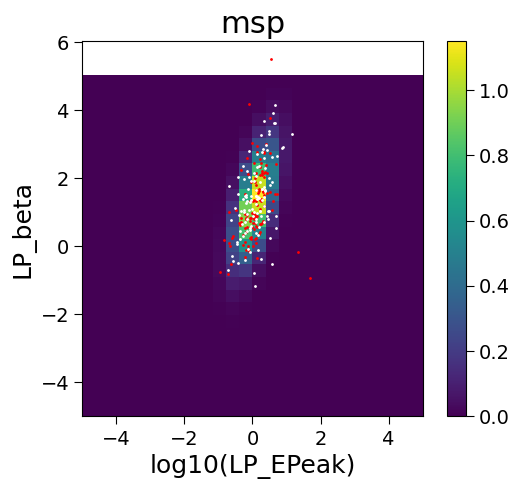

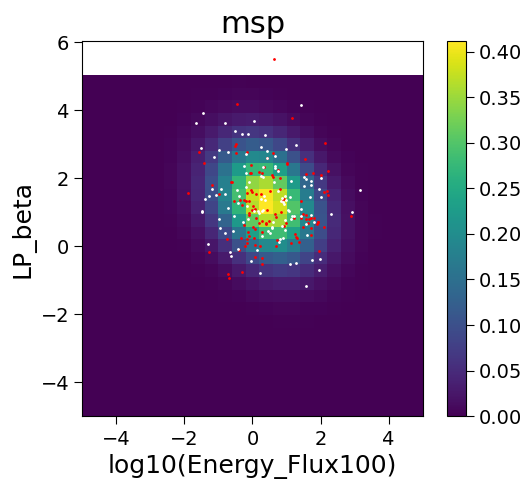

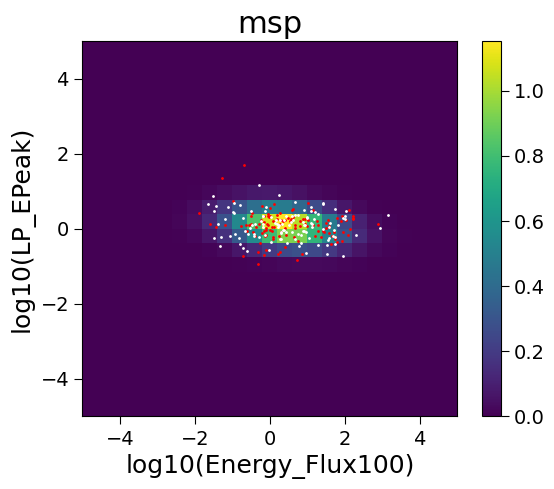

In [22]:
if len(features) == 3:
    extent = (-5, 5, -5, 5)
    for k in range(3):
        pyplot.figure()
        pyplot.imshow(np.sum(probs, axis=k).T, origin='lower', extent=extent)
        #inds = axis_dict_loc[k]
        inds = list(range(3))
        inds.pop(k)
        pyplot.plot(xs_test.T[inds[0]], xs_test.T[inds[1]], marker='o', ls='', color='red', ms=1)
        pyplot.plot(xs_rnd.T[inds[0]], xs_rnd.T[inds[1]], marker='o', ls='', color='white', ms=1)
        pyplot.xlabel(features[inds[0]])
        pyplot.ylabel(features[inds[1]])
        pyplot.xlim(-5, 5)
        pyplot.colorbar()
        pyplot.title(class_dict[key])

Models with 1 Gaussian kernel
000
Data: -3.13, Random -3.13 +- 0.0727
001
Data: -3.67, Random -3.45 +- 0.0478
010
Data: -4.37, Random -4.04 +- 0.1378
011
Data: -3.30, Random -3.06 +- 0.1121


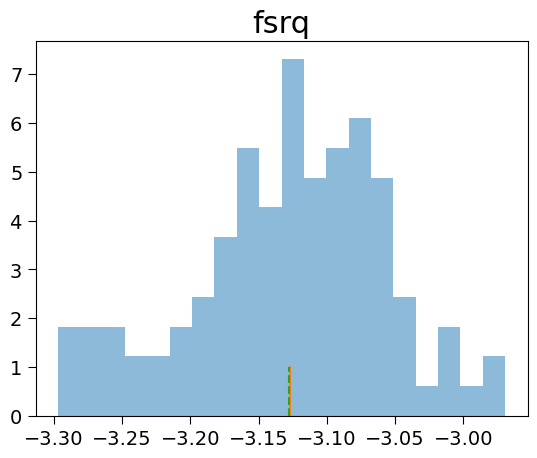

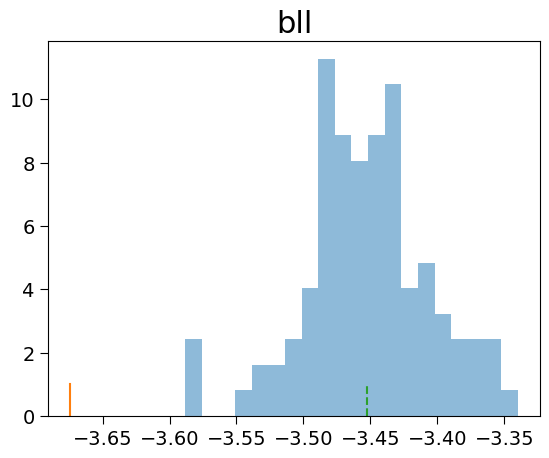

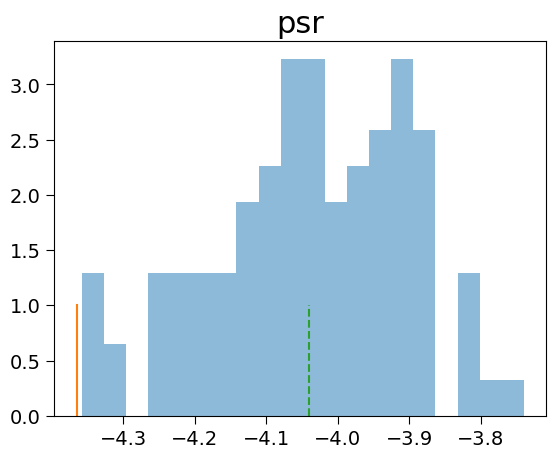

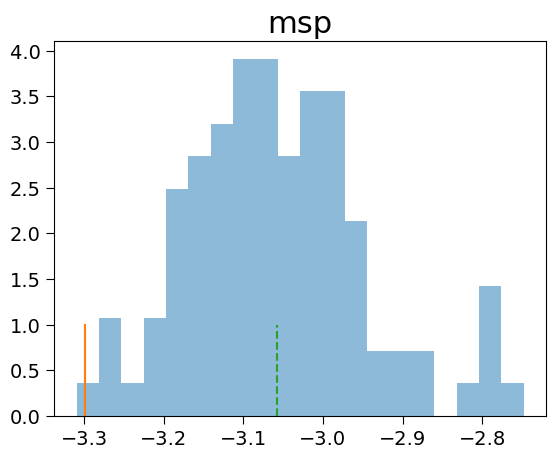

In [23]:
print('Models with 1 Gaussian kernel')
if kde_method == 'GMM':
    n_av = 100
else:
    n_av = 50
for key in tree_cat_dict.keys():
    TS_rnd = []
    cls = tree_cat_dict[key]
    clf_mask_dict[key] = util.get_cl_mask(cls, xdf, cname=class_name)
    xs = np.array(xdf[features][clf_mask_dict[key]])

    print(key)
    n_train = int(len(xs) * f_train)
    n_test = len(xs) - n_train
    TS = mdl_dict[key].score(xs[n_train:])
    if kde_method == 'GMM':
        xs_rnd = mdl_dict[key].sample(n_av * n_test)[0]
    elif kde_method == 'KDE_gauss':
        xs_rnd = mdl_dict[key].sample(n_av * n_test)
    rinds = np.random.choice(range(len(xs_rnd)), size=len(xs_rnd), replace=False)
    xs_rnd = xs_rnd[rinds]
    for n in range(n_av):
        TS_rnd.append(mdl_dict[key].score(xs_rnd[n * n_test : (n + 1) * n_test]))
    print('Data: %.2f, Random %.2f +- %.4f' %(TS, np.mean(TS_rnd), np.std(TS_rnd)))
    #print(TS_rnd)
    pyplot.figure()
    pyplot.hist(TS_rnd, bins=20, alpha=0.5, density=1)
    pyplot.plot([TS, TS], [0, 1], label='Data')
    TS_mean = np.mean(TS_rnd)
    pyplot.plot([TS_mean, TS_mean], [0, 1], ls='--', label='Rnd mean')
    pyplot.title(class_dict.get(key, key))

fsrq, bic nGMM min = 2
bll, bic nGMM min = 2
psr, bic nGMM min = 2
msp, bic nGMM min = 1


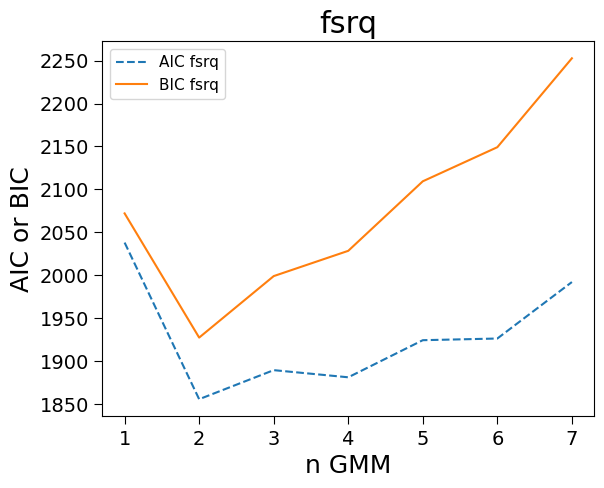

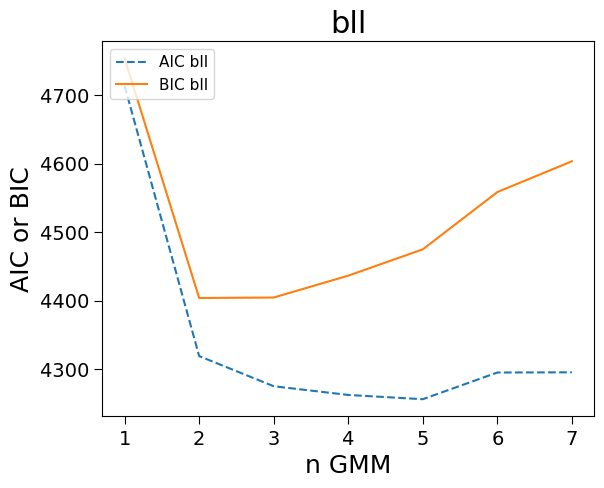

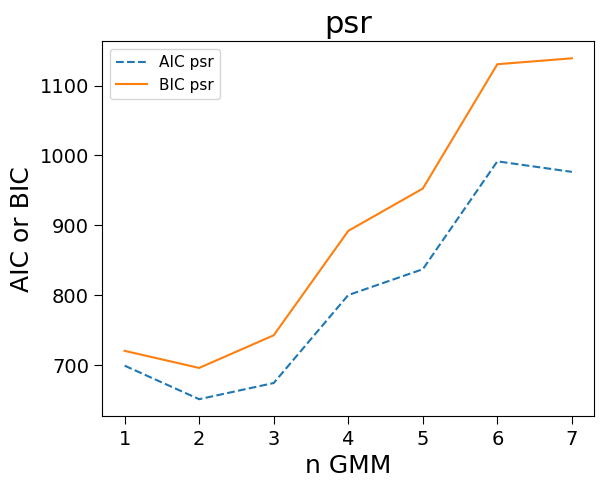

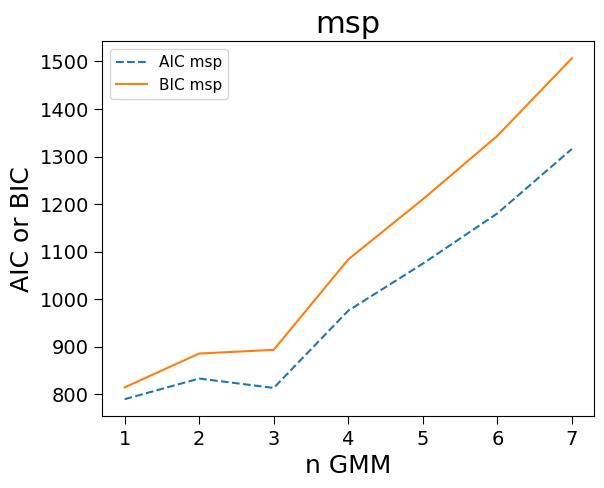

In [24]:
if kde_method == 'GMM':
    nGMM1_dict = {}
    imax = 7
    for key in tree_cat_dict.keys():
        pyplot.figure()
        pyplot.plot(nGMMs[:imax], aics[key][:imax], ls='--', label='AIC %s' % class_dict.get(key, key))
        pyplot.plot(nGMMs[:imax], bics[key][:imax], label='BIC %s' % class_dict.get(key, key))
        pyplot.xlabel('n GMM')
        pyplot.ylabel('AIC or BIC')
        pyplot.legend(loc='upper left')
        pyplot.title(class_dict.get(key, key))
        nmin = nGMMs[np.argmin(bics[key])]
        #nmin = nGMMs[np.argmin(aics[key])]
        nGMM1_dict[key] = nmin
        print('%s, bic nGMM min = %i' % (class_dict.get(key, key), nmin))
        #pyplot.ylim(0, 1500)

In [25]:
if kde_method == 'GMM':
    for key in tree_cat_dict.keys():
        cls = tree_cat_dict[key]
        clf_mask_dict[key] = util.get_cl_mask(cls, xdf, cname=class_name)
        nGMM = nGMM1_dict[key]
        mdl = GaussianMixture(n_components=nGMM, init_params='random', n_init=3, random_state=3)
        xs = np.array(xdf[features][clf_mask_dict[key]])
        mdl.fit(xs)
        mdl_dict[key] = mdl
    print(nGMM1_dict)

{'000': 2, '001': 2, '010': 2, '011': 1}


In [26]:
class_dict, nGMM1_dict

({'000': 'fsrq', '001': 'bll', '010': 'psr', '011': 'msp'},
 {'000': 2, '001': 2, '010': 2, '011': 1})

Best BIC models
000
Data: -2.76, Random -2.74 +- 0.0783
001
Data: -3.30, Random -3.25 +- 0.0488
010
Data: -3.82, Random -3.62 +- 0.1720
011
Data: -3.23, Random -3.15 +- 0.1157


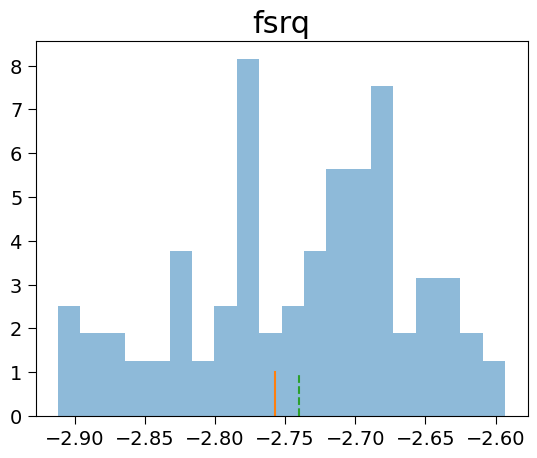

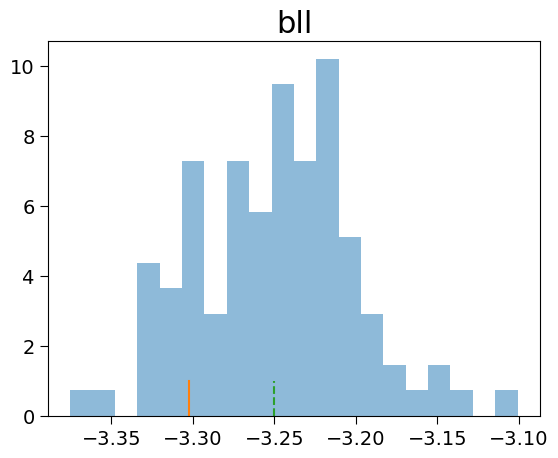

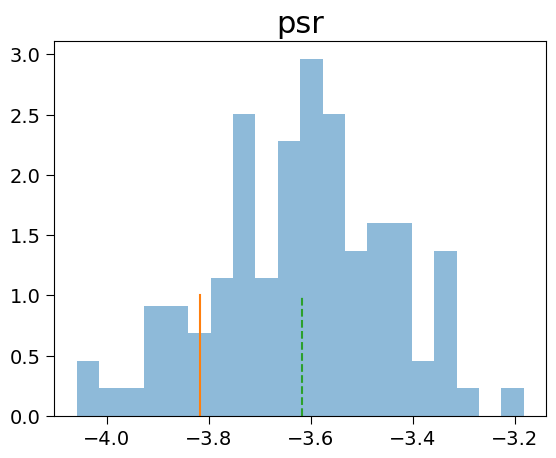

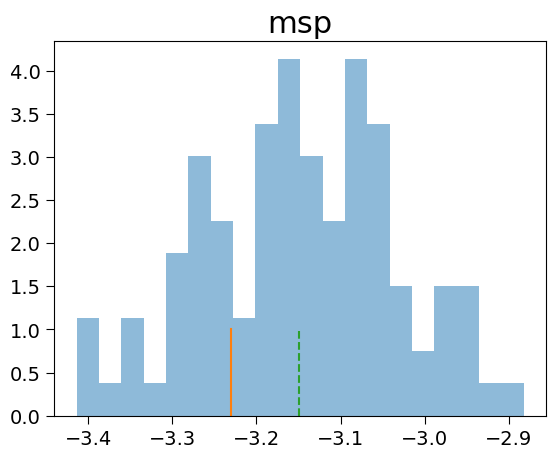

In [27]:
print('Best BIC models')
if kde_method == 'GMM':
    n_av = 100
else:
    n_av = 50
for key in tree_cat_dict.keys():
    TS_rnd = []
    cls = tree_cat_dict[key]
    clf_mask_dict[key] = util.get_cl_mask(cls, xdf, cname=class_name)
    xs = np.array(xdf[features][clf_mask_dict[key]])

    print(key)
    n_train = int(len(xs) * f_train)
    n_test = len(xs) - n_train
    TS = mdl_dict[key].score(xs[n_train:])
    if kde_method == 'GMM':
        xs_rnd = mdl_dict[key].sample(n_av * n_test)[0]
    elif kde_method == 'KDE_gauss':
        xs_rnd = mdl_dict[key].sample(n_av * n_test)
    rinds = np.random.choice(range(len(xs_rnd)), size=len(xs_rnd), replace=False)
    xs_rnd = xs_rnd[rinds]
    for n in range(n_av):
        TS_rnd.append(mdl_dict[key].score(xs_rnd[n * n_test : (n + 1) * n_test]))
    print('Data: %.2f, Random %.2f +- %.4f' %(TS, np.mean(TS_rnd), np.std(TS_rnd)))
    #print(TS_rnd)
    pyplot.figure()
    pyplot.hist(TS_rnd, bins=20, alpha=0.5, density=1)
    pyplot.plot([TS, TS], [0, 1], label='Data')
    TS_mean = np.mean(TS_rnd)
    pyplot.plot([TS_mean, TS_mean], [0, 1], ls='--', label='Rnd mean')
    pyplot.title(class_dict.get(key, key))

In [28]:
sum(unas_mask) + sum(clf_mask_all), len(xdf)

(3486, 5859)

In [29]:
#findex

In [30]:
if case == '4FGL-DR4_2class_PDF_no_coord_no_bcu_spp_pshift_nGauss1_npar4_signif_noflux':
    fname = 'log10(Signif_Avg)'
else:
    fname = 'log10(Energy_Flux100)'
findex = features.index(fname)
#ranges = [ranges_dict[feature] for feature in features]

#nbins = 25
#grids = [np.linspace(r[0], r[1], nbins[findex]) for r in ranges]
#xgrid = np.meshgrid(*grids, indexing='ij')
#xgrid = np.array([xx.flatten() for xx in xgrid]).T
dV = np.prod([v[1] - v[0] for v in grids])

xu = np.array(xdf[fname][unas_mask])
xu_all = np.array(xdf[features][unas_mask])
xa_all = np.array(xdf[features][clf_mask_all])
nodes = tree_cat_dict.keys()


def model(pars, pars_cov=None, npar=3, npar_cov=2, keys=tree_cat_dict.keys(), 
          mdl_func=sigmoid, mdl_func_cov=sigmoid0,
         ng_pars=0):
    if ng_pars == 0:
        pars_ = pars.reshape((len(pars)//npar, npar))
    else:
        pars_ = pars[:-ng_pars].reshape(((len(pars)-ng_pars)//npar, npar))
    if pars_cov is not None:
        pars_cov_ = pars_cov.reshape((len(pars0_dict_cov), npar_cov))
    def f(xs):
        res = 0.
        for k, key in enumerate(keys):
            res += mdl_func(pars_[k], xs.T[findex]) * np.exp(mdl_dict[key].score_samples(xs))
        if pars_cov is not None:
            for k, cname in enumerate(cov_shift_vnames):
                cfindex = features.index(cname)
                res *= sigmoid0(pars_cov_[k], xs.T[cfindex])
        if ng_pars > 0:
            pars_Gauss = pars[-ng_pars:]
            res += Gaussian_component(xs, pars_Gauss)
        return res
    return f

ng_pars = nGaussians * (1 + 2 * len(features))
mdl_args = {'mdl_func':mdl_func, 'mdl_func_cov':mdl_func_cov,
            'npar':npar, 'npar_cov':npar_cov, 'keys':tree_cat_dict.keys(),
           'ng_pars':ng_pars}

def objf(pars, pars_cov):
    # - log L = - sum_i log(mdl(x_i)) + N int mdl(x) dx
    #+ len(xu_all) * integrate.nquad(model_sep(pars), ranges)
    res = - np.sum(np.log(model(pars, pars_cov=pars_cov, **mdl_args)(xu_all))) 
    res += len(xu_all) * dV * np.sum(model(pars, pars_cov=pars_cov, **mdl_args)(xgrid))
    print(res)
    return res

def objf_cov(pars_cov, pars):
    res = - np.sum(np.log(model(pars, pars_cov=pars_cov, **mdl_args)(xu_all))) 
    res += len(xu_all) * dV * np.sum(model(pars, pars_cov=pars_cov, **mdl_args)(xgrid))
    print(res)
    return res


def TS(pars, pars_cov):
    def f(xs):
        res = - np.sum(np.log(model(pars, pars_cov, **mdl_args)(xs)))
        res += len(xs) * dV * np.sum(model(pars, pars_cov, **mdl_args)(xgrid))
        return res
    return f


pars0_dict = {}
bounds_dict = {}
for key in nodes:
    if mdl_func == sigmoid:
        xs = xdf[fname][clf_mask_dict[key]]
        x0 = np.median(xs)
        xw = np.std(xs) / 2.
        w0 = np.sum(clf_mask_dict[key]) / np.sum(clf_mask_all) * 0.5
        pars0 = [-1.5, x0, xw, np.log(w0), -0.1][:npar]
        bounds0 = [(-10, 2), (-5, 5), (0.05, 100), (-10, 10), (-1, 1)][:npar]
        pars0_dict[key] = np.array(pars0)
        bounds_dict[key] = np.array(bounds0)
    else:
        pars0_dict[key] = np.array([-0.5/(i+1) for i in range(npar)])
        bounds_dict[key] = np.array([(-10, 2) for i in range(npar)])
        
pars0 = np.array([pars0_dict[key] for key in pars0_dict.keys()]).flatten()
bounds = np.array([bounds_dict[key] for key in bounds_dict.keys()]).reshape((len(pars0), 2))

if ng_pars > 0:
    pars0_Gauss = [-1.5]
    bounds0_Gauss = [(-10, -0.5)]
    pars0_Gauss_dict = {'log10(Energy_Flux100)':-0.1, 'LP_index1000MeV':0.1, 
                        'LP_beta':0.1, 'log10(LP_EPeak)':-0.5, 'log10Epeak':-0.5}
    
    for i in range(len(features)):
        x0 = pars0_Gauss_dict.get(features[i], np.random.uniform(-0.2, 0.2))
        pars0_Gauss.extend([x0, 0.4])
        bounds0_Gauss.extend([(-1., 1), (0., 3.)])
    pars0_dict['Gauss'] = np.array(pars0_Gauss)
    bounds_dict['Gauss'] = np.array(bounds0_Gauss)
    pars0 = np.append(pars0, pars0_Gauss)
    bounds = np.append(bounds.flatten(), bounds_dict['Gauss'].flatten()).reshape(len(pars0), 2)

#cov_shift_vnames = ['log10(Energy_Flux100)', 'LP_index1000MeV', 'LP_beta']
#cov_shift_vnames = [ 'LP_index1000MeV', 'LP_beta']
cov_shift_vnames = []
pars0_dict_cov = {}
bounds_dict_cov = {}
for cname in cov_shift_vnames:
    x0 = np.mean(ranges_dict[cname])
    xw = - np.std(ranges_dict[cname]) / 2.
    if cname in ['log10(Energy_Flux100)']:
        xw *= -1
    pars0_dict_cov[cname] = np.array([x0, xw])
    bounds_dict_cov[cname] = np.array([(ranges_dict[cname][0] - 3, ranges_dict[cname][1] + 3), 
                                       (0.05, 1000)
                                      ])

    
pars0_cov = np.array([pars0_dict_cov[key] for key in pars0_dict_cov.keys()]).flatten()
bounds_cov = np.array([bounds_dict_cov[key] for key in bounds_dict_cov.keys()]).reshape((len(pars0_cov), 2))


In [31]:
bounds_dict['Gauss']

array([[-10. ,  -0.5],
       [ -1. ,   1. ],
       [  0. ,   3. ],
       [ -1. ,   1. ],
       [  0. ,   3. ],
       [ -1. ,   1. ],
       [  0. ,   3. ]])

In [32]:
pars0

array([-1.5       ,  0.49237926,  0.50999436, -1.96933247, -1.5       ,
       -0.12189564,  0.49621704, -1.28631393, -1.5       ,  1.78326992,
        0.46421876, -3.38872678, -1.5       ,  0.33898371,  0.47633029,
       -2.98754434, -1.5       , -0.1       ,  0.4       , -0.5       ,
        0.4       ,  0.1       ,  0.4       ])

In [33]:
mdl_args

{'mdl_func': <function __main__.sigmoid(pars, x)>,
 'mdl_func_cov': <function __main__.sigmoid0(pars, x)>,
 'npar': 4,
 'npar_cov': 2,
 'keys': dict_keys(['000', '001', '010', '011']),
 'ng_pars': 7}

In [34]:
pars0_dict

{'000': array([-1.5       ,  0.49237926,  0.50999436, -1.96933247]),
 '001': array([-1.5       , -0.12189564,  0.49621704, -1.28631393]),
 '010': array([-1.5       ,  1.78326992,  0.46421876, -3.38872678]),
 '011': array([-1.5       ,  0.33898371,  0.47633029, -2.98754434]),
 'Gauss': array([-1.5, -0.1,  0.4, -0.5,  0.4,  0.1,  0.4])}

Pure prior shift
$$
p_{unas}(\theta) = \sum_{k} f_k p^k_{assoc}(\theta)
$$
Flux-dependent prior shift model
$$
p_{unas}(\theta) = \sum_{k} f_k(\log EF) p^k_{assoc}(\theta)
$$
Flux-dependent prior shift plus covariate shift model
$$
p_{unas}(\theta) = \sum_{k} f_k(\log EF) p^k_{assoc}(\theta) \prod_i g_i(\theta_i)
$$
where $k$ is the class label (e.g., Galactic or extragalactic). $f_k(\log F)$ is a flux-dependent prior shift (or class-dependent covariate shift), $p^k_{assoc}(\theta)$ is the distribution of associated sources in class $k$ as a function of input variables $\theta = [\log10(Energy\_Flux100), LP\_index1000MeV, LP\_beta]$.
Functions $g_i(\theta_i)$ describe (class-independent) covariate shifts of input variables $\theta_i$.
$f_k(\log EF)$ is modeled as a general sigmoid plus a constant
$$
\sigma(x) = \frac{a}{1 + e^{(x - b) / c}} + d
$$
which interpolates from $a + d$ at minus infinity to $d$ at plus infinity.
While $g_i(\theta_i)$ is modeled by sigmoid normalized to 1 in the middle
$$
\sigma(x) = \frac{2}{1 + e^{(x - b) / c}}
$$


In [35]:
bounds

array([[-1.e+01,  2.e+00],
       [-5.e+00,  5.e+00],
       [ 5.e-02,  1.e+02],
       [-1.e+01,  1.e+01],
       [-1.e+01,  2.e+00],
       [-5.e+00,  5.e+00],
       [ 5.e-02,  1.e+02],
       [-1.e+01,  1.e+01],
       [-1.e+01,  2.e+00],
       [-5.e+00,  5.e+00],
       [ 5.e-02,  1.e+02],
       [-1.e+01,  1.e+01],
       [-1.e+01,  2.e+00],
       [-5.e+00,  5.e+00],
       [ 5.e-02,  1.e+02],
       [-1.e+01,  1.e+01],
       [-1.e+01, -5.e-01],
       [-1.e+00,  1.e+00],
       [ 0.e+00,  3.e+00],
       [-1.e+00,  1.e+00],
       [ 0.e+00,  3.e+00],
       [-1.e+00,  1.e+00],
       [ 0.e+00,  3.e+00]])

In [ ]:
if ng_pars > 0:
    maxiter = 5000
else:
    maxiter = 1000
res_prior_all = minimize(objf, pars0, args=(None), bounds=bounds,
               method='nelder-mead', options={'xatol': 0.01, 'disp': True, 'maxiter':maxiter})

5469.314555588605
5466.464265883696
5469.569221722583
5469.265781412404
5464.856879618073
5463.552597901739
5469.026137221446
5469.343893522556
5456.346720233738
5474.679045412682
5468.031904296919
5470.216813291655
5470.724233600268
5475.575684168336
5467.733076940293
5468.808795832165
5476.099945060472
5468.563117150199
5471.397899966193
5465.747417018276
5472.458265445473
5473.63333771308
5467.979065283534
5463.975934580395
5460.111095829097
5460.043326684972
5459.841664619975
5459.6495626158685
5460.210757508354
5459.696240615185
5459.4663241327935
5458.9943228888305
5458.734720567552
5458.036609806784
5457.098315112949
5456.112281044138
5449.713270507353
5454.676653012038
5453.692769690007
5453.156112678486
5452.283740658696
5450.5949651856645
5449.355290698182
5440.454888001013
5448.620967600913
5447.943083490767
5447.660241315588
5446.677107333813
5445.821246942471
5447.928813453827
5445.800684495153
5445.205949328621
5444.142119154025
5443.073342261152
5441.9721949482055
5440.2

/var/folders/mb/yxqk032n4lvgsvnl3lqzbwvr0000gn/T/ipykernel_23048/1903750230.py:5: RuntimeWarning: Maximum number of iterations has been exceeded.
  res_prior_all = minimize(objf, pars0, args=(None), bounds=bounds,


In [37]:
res_prior = res_prior_all.x
print(res_prior)
print(np.exp(res_prior))

[-6.6134931   3.736673    2.86843566 -2.08017262 -1.8314831   0.0546502
  0.22820255 -8.94768059 -0.82559527 -0.60621435  0.92074199 -4.27921406
 -6.46997442 -0.19924684  0.10378017 -1.43028999 -0.71830239  0.38887369
  0.49797313 -0.37470957  0.28403011  0.65403309  0.77288665]
[1.34213573e-03 4.19581628e+01 1.76094495e+01 1.24908648e-01
 1.60175835e-01 1.05617110e+00 1.25633977e+00 1.30038423e-04
 4.37974200e-01 5.45411702e-01 2.51115295e+00 1.38535458e-02
 1.54926536e-03 8.19347620e-01 1.10935655e+00 2.39239535e-01
 4.87579274e-01 1.47531819e+00 1.64538291e+00 6.87488916e-01
 1.32847294e+00 1.92328197e+00 2.16600975e+00]


In [38]:
bounds_cov, pars0_cov

(array([], shape=(0, 2), dtype=float64), array([], dtype=float64))

In [39]:
if len(cov_shift_vnames) > 0:
    res_cov_all = minimize(objf_cov, pars0_cov, bounds=bounds_cov, args=(res_prior),
                   method='nelder-mead', options={'xatol': 0.01, 'disp': True, 'maxiter':200})
    res_cov = res_cov_all.x
else:
    res_cov = None

In [40]:
res_cov, res_prior

(None,
 array([-6.6134931 ,  3.736673  ,  2.86843566, -2.08017262, -1.8314831 ,
         0.0546502 ,  0.22820255, -8.94768059, -0.82559527, -0.60621435,
         0.92074199, -4.27921406, -6.46997442, -0.19924684,  0.10378017,
        -1.43028999, -0.71830239,  0.38887369,  0.49797313, -0.37470957,
         0.28403011,  0.65403309,  0.77288665]))

In [96]:

if ng_pars == 0:
    pars_fit_prior = res_prior.reshape((len(pars0_dict), npar))
    pars_fit_Gauss = []
    plot_text = plot_text0
else:
    pars_fit_prior = res_prior[:-ng_pars].reshape((len(pars0_dict) - 1, npar))
    pars_fit_Gauss = res_prior[-ng_pars:]
    ngauss_src = len(xu_all) * np.exp(pars_fit_Gauss[0])
    if show_Gaussian:
        plot_text = '%s\n #Gauss = %i (%.1f%%)' % \
                    (plot_text0, ngauss_src, 100*ngauss_src/len(xu_all))
    else:
        plot_text = plot_text0
    print('Gaussian parameters')
    print(pars_fit_Gauss)
if len(cov_shift_vnames) > 0:
    pars_fit_cov = res_cov.reshape((len(pars0_dict_cov), npar_cov))
else:
    pars_fit_cov = None
print('Prior shift params')
print(pars_fit_prior)
print('Cov shift params')
print(pars_fit_cov)
print('Number of SGU-like sources: %.2f' % ngauss_src)

Gaussian parameters
[-0.71830239  0.38887369  0.49797313 -0.37470957  0.28403011  0.65403309
  0.77288665]
Prior shift params
[[-6.6134931   3.736673    2.86843566 -2.08017262]
 [-1.8314831   0.0546502   0.22820255 -8.94768059]
 [-0.82559527 -0.60621435  0.92074199 -4.27921406]
 [-6.46997442 -0.19924684  0.10378017 -1.43028999]]
Cov shift params
None
Number of SGU-like sources: 572.91


In [97]:
TS_func = TS(res_prior, res_cov)

In [98]:
res_prior

array([-6.6134931 ,  3.736673  ,  2.86843566, -2.08017262, -1.8314831 ,
        0.0546502 ,  0.22820255, -8.94768059, -0.82559527, -0.60621435,
        0.92074199, -4.27921406, -6.46997442, -0.19924684,  0.10378017,
       -1.43028999, -0.71830239,  0.38887369,  0.49797313, -0.37470957,
        0.28403011,  0.65403309,  0.77288665])

In [99]:
mdl_args['keys'] = nodes
PDF = dV * model(res_prior, res_cov,  **mdl_args)(xgrid)
keys0 = mdl_args['keys']
ng_pars0 = mdl_args['ng_pars']
PDF_comps = {}
for k, key in enumerate(tree_cat_dict.keys()):
    mdl_args['keys'] = [key]
    mdl_args['ng_pars'] = 0
    if res_cov is None:
        PDF_comps[key] = dV * model(res_prior[npar*k:npar*(k+1)], res_cov, **mdl_args)(xgrid)
    else:
        mdl_loc = model(res_prior[npar*k:npar*(k+1)], res_cov[npar_cov*k:npar_cov*k+1], **mdl_args)(xgrid)
        PDF_comps[key] = dV * mdl_loc
    if ng_pars > 0:
        PDF_comps['Gauss'] = dV * Gaussian_component(xgrid, pars_fit_Gauss)
mdl_args['keys'] = keys0
mdl_args['ng_pars'] = ng_pars0

In [100]:
# create a catalog with class probabilities
folder_out = '../results/%s_probabilistic_catalogs/' % util.get_cat_descr(cdict, add_pshift=0)
folder_gu = '../Fermi_SGU/GU_git/data_in/ML_catalogs/'
if not os.path.isdir(folder_out):
    print('make new dir')
    print(folder_out)
    os.mkdir(folder_out)
fn_out = '%s%s_%s' % (folder_out, util.get_cat_descr(cdict, add_pshift=1), 'prob_cat.csv')
fn_gu = '%s%s_%s' % (folder_gu, util.get_cat_descr(cdict, add_pshift=1), 'prob_cat.csv')

# add features for convenience
df_out = xdf0[features].copy()
for feature in add_out_features:
    df_out[feature] = xdf0[feature]
# add probabilities for the components
if 1:
    alg = cdict['class_alg']
    xs = np.array(xdf[features])
    clms = []
    ng_pars0 = mdl_args['ng_pars']
    for k, key in enumerate(tree_cat_dict.keys()):
        mdl_args['keys'] = [key]
        mdl_args['ng_pars'] = 0
        clm = '%i_%s' % (k+1, alg)
        clms.append(clm)
        df_out[clm] = model(res_prior[npar*k:npar*(k+1)], res_cov, **mdl_args)(xs)
    mdl_args['ng_pars'] = ng_pars0
    
    if ng_pars > 0:
        clm = 'Gauss_PDF'
        clms.append(clm)
        df_out[clm] = Gaussian_component(xs, pars_fit_Gauss)

    # calculate conditional probabilities
    tot_mdl = np.sum(df_out[clms], axis=1)
    for clm in clms:
        df_out[clm] /= tot_mdl
if save_results:
    print('Save the prob catalog to file:')
    print(fn_out)
    df_out.to_csv(fn_out)
    if copy2gu:
        cmd = 'cp %s %s' % (fn_out, fn_gu)
        print(cmd)
        os.system(cmd)

Save the prob catalog to file:
../results/4FGL-DR4_v34_4classes_GMM_no_bcu_spp_no_coord_features_probabilistic_catalogs/4FGL-DR4_v34_4classes_GMM_no_bcu_spp_no_coord_features_unas_unk_prior_shift_npar4_1Gauss_prob_cat.csv


In [101]:
np.random.seed(0)
sample = np.random.poisson(len(xu_all) * PDF)

(array([216.,  84.,  39.,  21.,  18.,   6.,  10.,   5.,   5.,   2.,   5.,
          4.,   2.,   1.,   3.,   0.,   1.,   1.]),
 array([ 1.,  2.,  3.,  4.,  5.,  6.,  7.,  8.,  9., 10., 11., 12., 13.,
        14., 15., 16., 17., 18., 19.]),
 <BarContainer object of 18 artists>)

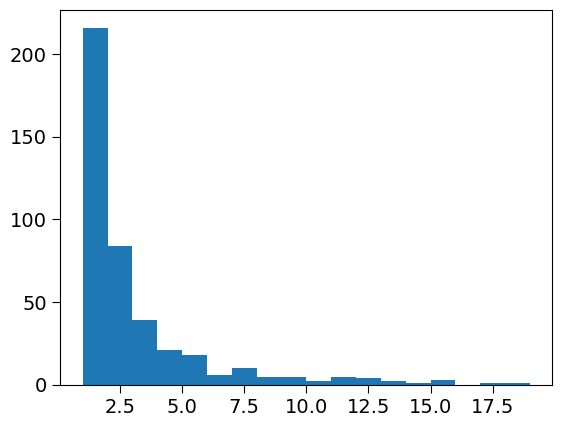

In [102]:
pyplot.hist(sample, bins=np.arange(1, 20))

In [103]:
max(sample)

21

In [104]:
xsample = []
for k in range(1, max(sample) + 1):
    xsample_loc = xgrid[sample == k]
    for i in range(k):
        xsample.extend(xsample_loc)
xsample = np.array(xsample)

In [105]:
rinds = np.random.randint(len(xsample), size=len(xu_all))
rinds.sort()
rinds = list(rinds)

In [106]:
xsample = xsample[rinds]

In [107]:
xsample.shape, xu_all.shape

((1175, 3), (1175, 3))

In [108]:
# TS = - log L: smaller TS is better, negative delta TS - overfitting
TS_func(xsample), TS_func(xu_all), TS_func(xu_all) - TS_func(xsample)

(6336.31393036902, 6322.9060832565765, -13.40784711244396)

In [109]:
ng_pars

7

In [110]:
np.min(xu_all[:,0]), np.max(xu_all[:,0])

(-1.6672706966561919, 3.093189886102891)

In [111]:
np.min(xsample[:,0]), np.max(xsample[:,0])

(-3.2, 3.2)

In [112]:
pars0_dict

{'000': array([-1.5       ,  0.49237926,  0.50999436, -1.96933247]),
 '001': array([-1.5       , -0.12189564,  0.49621704, -1.28631393]),
 '010': array([-1.5       ,  1.78326992,  0.46421876, -3.38872678]),
 '011': array([-1.5       ,  0.33898371,  0.47633029, -2.98754434]),
 'Gauss': array([-1.5, -0.1,  0.4, -0.5,  0.4,  0.1,  0.4])}

In [113]:
pars_fit_prior

array([[-6.6134931 ,  3.736673  ,  2.86843566, -2.08017262],
       [-1.8314831 ,  0.0546502 ,  0.22820255, -8.94768059],
       [-0.82559527, -0.60621435,  0.92074199, -4.27921406],
       [-6.46997442, -0.19924684,  0.10378017, -1.43028999]])

In [114]:
mean_std_dict[fname]

{'mean': -11.400959897593447, 'std': 0.4504107244928136}

000 {'color': '#1f77b4', 'ls': '--'}
001 {'color': '#ff7f0e', 'ls': ':'}
010 {'color': '#2ca02c', 'ls': (0, (5, 4))}
011 {'color': '#d62728', 'ls': (0, (4, 5, 1, 5))}
save figure to file: ../plots/prior_shift/4FGL-DR4_GMM_PDF_no_coord_no_bcu_spp_pshift_nGauss1_npar4_sigmoid_npar4_unas_unk_unas_below_b10_nclass4_1Gauss//prior_shift_fit_4FGL-DR4_GMM_PDF_no_coord_no_bcu_spp_pshift_nGauss1_npar4_sigmoid_npar4_unas_unk_unas_below_b10_nclass4_1Gauss_log10(Energy_Flux100).pdf


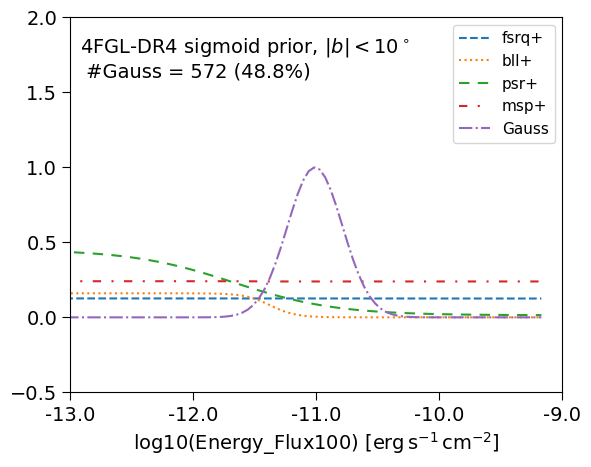

In [115]:
show_init = 0
pyplot.figure()
ax = pyplot.subplot(1, 1, 1)
for k, key in enumerate(nodes):
    inorm = lambda x: inv_normalize_feature(x, mean_std_dict[fname])
    if class_dict.get(key) in ['Gauss', 'Extragalactic', 'Galactic']:
        #label = '%s (%i)' % (class_dict[key], sum(mask))
        label = '%s' % (class_dict[key])
    else:
        label = '%s+' % class_dict.get(key, key)
    
    if show_init:
        label += ' fit'
    pyplot.plot(inorm(grids_plot[findex]), mdl_func(pars_fit_prior[k], grids_plot[findex]), 
                label=label, **mdl_style_dict[key])
    print(key, mdl_style_dict[key])
    if show_init:
        pyplot.plot(inorm(grids_plot[findex]), mdl_func(pars0_dict[key], grids_plot[findex]),
                    label='%s+ init' % class_dict.get(key, key), **mdl_style_dict[key])

if show_Gaussian and len(pars_fit_Gauss) > 0:
    mu = pars_fit_Gauss[1::2][findex] + mean_std_dict[fname]['mean']
    sigma = pars_fit_Gauss[2::2][findex] * mean_std_dict[fname]['std']
    xs = inorm(grids_plot[findex])
    ys = np.exp(-(xs - mu)**2/(2. * sigma**2))
    key = 'Gauss'
    pyplot.plot(xs, ys, label=key, **mdl_style_dict[key])
    


pyplot.legend()
#pyplot.grid()
#pyplot.title('Prior shift')
pyplot.xlabel(flabel_dict.get(fname, fname), fontsize=14)
pyplot.xlim(-13, -9)
xticks = np.arange(-13, -8.9, 1)
pyplot.xticks(ticks=xticks, labels=xticks)
              
if not show_Gaussian:
    pyplot.ylim(-0.5, 1.)
elif nGaussians == 0:
    pyplot.ylim(-0.5, 2.)
else:
    pyplot.ylim(-0.5, 2.)    
ax.text(0.02, 0.95, plot_text, #fontsize=10, 
        transform=ax.transAxes,
        horizontalalignment='left', verticalalignment='top')


if save_plots:
    fn = '%s/prior_shift_fit_%s_%s.pdf' % (plots_folder, descr_str, fname)
    print('save figure to file: %s' % (fn))
    pyplot.savefig(fn, metadata=fig_meta)
    if save_png:
        fn_png = fn.replace('.pdf', '.png')
        print('save figure to file: %s' % (fn_png))
        pyplot.savefig(fn_png, metadata=fig_meta)

for k, key in enumerate(cov_shift_vnames):
    pyplot.figure()
    cfindex = features.index(key)
    pyplot.plot(grids[cfindex], mdl_func_cov(pars_fit_cov[k], grids[cfindex]), 
                label='%s fit' % class_dict.get(key, key))
    pyplot.plot(grids[cfindex], mdl_func_cov(pars0_dict_cov[key], grids[cfindex]), ls='--', 
                label='%s init' % class_dict.get(key, key))
    print(key)
    print(pars0_dict_cov[key])
    
    #res *= sigmoid(pars_[k + len(nodes)], xs.T[cfindex])

    pyplot.legend()
    pyplot.grid()
    pyplot.title('Cov shift %s' % key)
    if save_plots:
        fn = '%s/cov_shift_fit_%s_%s.pdf' % (plots_folder, descr_str, fname)
        print('save figure to file: %s' % (fn))
        pyplot.savefig(fn, metadata=fig_meta)
        if save_png:
            fn_png = fn.replace('.pdf', '.png')
            print('save figure to file: %s' % (fn_png))
            pyplot.savefig(fn_png, metadata=fig_meta)



In [116]:
for k, feature in enumerate(features):
    mu = pars_fit_Gauss[1::2][k] + mean_std_dict[feature]['mean']
    sigma = pars_fit_Gauss[2::2][k] * mean_std_dict[feature]['std']
    print('%s: %.4f +- %.4f' % (feature, mu, sigma))


log10(Energy_Flux100): -11.0121 +- 0.2243
log10(LP_EPeak): -0.3875 +- 0.2435
LP_beta: 0.8535 +- 0.1102


In [117]:
nbins

[25, 26, 27]

In [118]:
mdlf = (len(xsample) * PDF).reshape(nbins)
mdlf_comps = {}
for key in PDF_comps.keys():
    mdlf_comps[key] = (len(xsample) * PDF_comps[key]).reshape(nbins)

In [119]:
mdl_style_dict

{'000': {'color': '#1f77b4', 'ls': '--'},
 '001': {'color': '#ff7f0e', 'ls': ':'},
 '010': {'color': '#2ca02c', 'ls': (0, (5, 4))},
 '011': {'color': '#d62728', 'ls': (0, (4, 5, 1, 5))},
 'Gauss': {'color': '#9467bd', 'ls': '-.'},
 'unassoc': {'color': 'cornflowerblue', 'ls': (0, (3, 1, 1, 1, 1, 1))},
 'assoc': {'color': '#e377c2', 'ls': '-'},
 'model': {'color': '#7f7f7f', 'ls': '--'},
 'GU': {'color': 'limegreen'}}

In [120]:
if 0:
    if len(features) == 3:
        axis_dict = {0:(0, 2), 1:(1, 2), 2:(0, 1)}
    elif len(features) == 4:
        axis_dict = {0:(0, 2, 3), 1:(1, 2, 3), 2:(0, 1, 3), 3:(0, 1, 2)}
        #axis_dict = {0:(1, 2, 3), 1:(0, 2, 3), 2:(0, 1, 3), 3:(0, 1, 2)}
    #xgrid[:, 1].reshape((nbins, nbins, nbins)).mean(axis=(1, 2))

In [121]:
features

['log10(Energy_Flux100)', 'log10(LP_EPeak)', 'LP_beta']

Low lat sources
log10(Energy_Flux100), mean mdl sample = 0.39, mean data = 0.40
mean assoc = 0.32
save figure to file: ../plots/prior_shift/4FGL-DR4_GMM_PDF_no_coord_no_bcu_spp_pshift_nGauss1_npar4_sigmoid_npar4_unas_unk_unas_below_b10_nclass4_1Gauss//prior_shift_model_4FGL-DR4_GMM_PDF_no_coord_no_bcu_spp_pshift_nGauss1_npar4_sigmoid_npar4_unas_unk_unas_below_b10_nclass4_1Gauss_log10(Energy_Flux100).pdf
log10(LP_EPeak), mean mdl sample = -0.23, mean data = -0.23
mean assoc = 0.11
save figure to file: ../plots/prior_shift/4FGL-DR4_GMM_PDF_no_coord_no_bcu_spp_pshift_nGauss1_npar4_sigmoid_npar4_unas_unk_unas_below_b10_nclass4_1Gauss//prior_shift_model_4FGL-DR4_GMM_PDF_no_coord_no_bcu_spp_pshift_nGauss1_npar4_sigmoid_npar4_unas_unk_unas_below_b10_nclass4_1Gauss_log10(LP_EPeak).pdf
LP_beta, mean mdl sample = 0.68, mean data = 0.55
mean assoc = -0.30
save figure to file: ../plots/prior_shift/4FGL-DR4_GMM_PDF_no_coord_no_bcu_spp_pshift_nGauss1_npar4_sigmoid_npar4_unas_unk_unas_below_b10_nclas

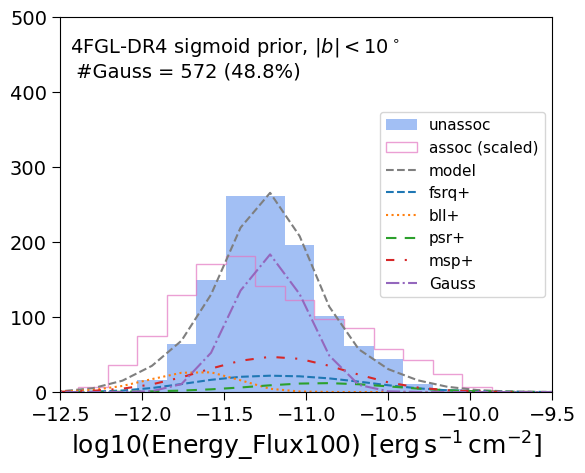

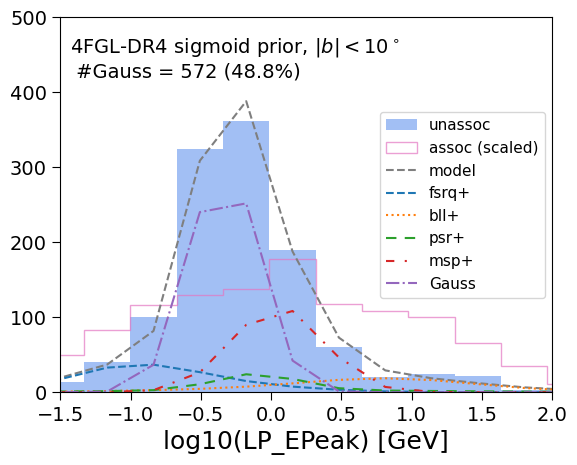

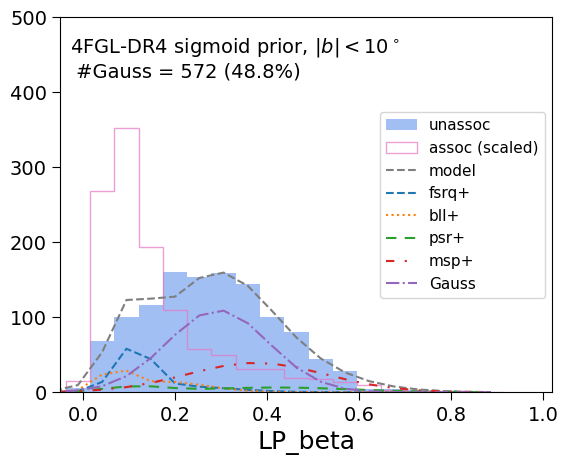

In [122]:
print(ROI_name)

xlims = {'log10(Energy_Flux100)':(-12.5, -9.5), 'log10(LP_EPeak)':(-1.5, 2), 'LP_beta':(-0.05, 1.02)}    

weights = len(xu_all) / len(xa_all) * np.ones(len(xa_all))

models = list(PDF_comps.keys())
if 'Gauss' in models:
    models.remove('Gauss')
    models.append('Gauss')


show_sample = 0
for k, feature in enumerate(features):
    # inverse norm function
    inorm = lambda x: inv_normalize_feature(x, mean_std_dict[feature])
    
    pyplot.figure()
    ax = pyplot.subplot(1, 1, 1)
    if show_sample:
        pyplot.hist(inorm(xsample[:,k]), bins=inorm(grids_b[k]), alpha=0.5, label='model sample')
    pyplot.hist(inorm(xu_all[:,k]), bins=inorm(grids_b[k]), alpha=0.6, label='unassoc', **mdl_style_dict['unassoc'])
    pyplot.hist(inorm(xa_all[:,k]), weights=weights, bins=inorm(grids_b[k]), 
                alpha=0.7, histtype='step', label='assoc (scaled)', **mdl_style_dict['assoc'])
    print('%s, mean mdl sample = %.2f, mean data = %.2f' % (feature, np.mean(xsample[:,k]), np.mean(xu_all[:,k])))
    print('mean assoc = %.2f' % np.mean(xa_all[:,k]))
    inds = list(range(len(features)))
    inds.pop(k)
    #inds = axis_dict[k]
    mdlf_marg = np.sum(mdlf, axis=tuple(inds))
    pyplot.plot(inorm(grids[k]), mdlf_marg, label='model', **mdl_style_dict['model'])
    for m, key in enumerate(models):
        mdlf_marg_comp = np.sum(mdlf_comps[key], axis=tuple(inds))
        label = '%s' % class_dict.get(key, key)
        if label not in ['Gauss', 'Extragalactic', 'Galactic']:
        #if label != 'Gauss':
            label += '+'
        pyplot.plot(inorm(grids[k]), mdlf_marg_comp, label=label, **mdl_style_dict[key])
    
    if ncomp > 2:
        ax.text(0.02, 0.95, plot_text, #fontsize=10, 
                transform=ax.transAxes,
                horizontalalignment='left', verticalalignment='top')
    
    if ncomp > 2:
        if llat_ROI:
            pyplot.ylim(0, 500)
        elif hlat_ROI:
            pyplot.ylim(0, 200)
        elif unas_sources == 'unas_unk':
            pyplot.ylim(0, 700)
        elif case.find('no_bcu') == -1:
            pyplot.ylim(0, 700)
        else:
            pyplot.ylim(0, 1000)
    if feature in xlims:
        pyplot.xlim(xlims[feature])
    pyplot.xlabel(flabel_dict.get(feature, feature))
    pyplot.legend()
    #print(feature)
    #print(np.histogram(xdf[feature]))
    if save_plots:
        fn = '%s/prior_shift_model_%s_%s.pdf' % (plots_folder, descr_str, feature)
        print('save figure to file: %s' % (fn))
        pyplot.savefig(fn, metadata=fig_meta)
        if save_png:
            fn_png = fn.replace('.pdf', '.png')
            print('save figure to file: %s' % (fn_png))
            pyplot.savefig(fn_png, metadata=fig_meta)


In [68]:
mdlf_marg_comp = np.sum(mdlf_comps[key], axis=tuple(inds))
key, mdlf_marg_comp

('Gauss',
 array([1.47018361e-09, 3.89140646e-08, 8.18675444e-07, 1.36894841e-05,
        1.81941825e-04, 1.92197689e-03, 1.61374134e-02, 1.07693586e-01,
        5.71236433e-01, 2.40830845e+00, 8.07009167e+00, 2.14938877e+01,
        4.55010724e+01, 7.65593854e+01, 1.02387136e+02, 1.08833475e+02,
        9.19495799e+01, 6.17457614e+01, 3.29560157e+01, 1.39808121e+01,
        4.71411582e+00, 1.26339236e+00, 2.69120258e-01, 4.55642982e-02,
        6.13159031e-03, 6.55830668e-04, 5.57545690e-05]))

In [69]:
if 'log10(LP_EPeak)' in features:
    ind_epeak = features.index('log10(LP_EPeak)')
    nbins_Epeak = nbins[ind_epeak]
    bins_epeak = np.linspace(-1.2, 2.2, nbins_Epeak)
    if feature_mode.find('Toby') > -1:
        ind_k = features.index('LP_index1000MeV')
        d_k = features.index('d')
        #logEpeak_unas = log10Epeak(xu_all[:, ind_k], d=xu_all[:, d_k], logEp_min=-1.1, logEp_max=2.1)
        inorm_d = lambda x: inv_normalize_feature(x, mean_std_dict['d'])
        inorm_n = lambda x: inv_normalize_feature(x, mean_std_dict['LP_index1000MeV'])
        logEpeak_unas = log10Epeak(inorm_n(xu_all[:, ind_k]), d=inorm_d(xu_all[:, d_k]), 
                                   logEp_min=-1.1, logEp_max=2.1)
        logEpeak_unas_check = log10Epeak(logEp=xdf['log_epeak'][unas_mask], logEp_min=-1.1, logEp_max=2.1)
        logEpeak_assoc = log10Epeak(inorm_n(xa_all[:, ind_k]), d=inorm_d(xa_all[:, d_k]), 
                                    logEp_min=-1.1, logEp_max=2.1)
        logEpeak_sample = log10Epeak(inorm_n(xsample[:, ind_k]), d=inorm_d(xsample[:, d_k]), 
                                     logEp_min=-1.1, logEp_max=2.1)
    elif feature_mode.find('spec_features') > -1:
        ind_k = features.index('LP_index1000MeV')
        beta_k = features.index('LP_beta')
        inorm_beta = lambda x: inv_normalize_feature(x, mean_std_dict['LP_beta'])
        inorm_n = lambda x: inv_normalize_feature(x, mean_std_dict['LP_index1000MeV'])
        logEpeak_unas = log10Epeak(inorm_n(xu_all[:, ind_k]), beta=inorm_beta(xu_all[:, beta_k]), 
                                   logEp_min=-1.1, logEp_max=2.1)
        logEpeak_assoc = log10Epeak(inorm_n(xa_all[:, ind_k]), beta=inorm_beta(xa_all[:, beta_k]), 
                                    logEp_min=-1.1, logEp_max=2.1)
        logEpeak_sample = log10Epeak(inorm_n(xsample[:, ind_k]), beta=inorm_beta(xsample[:, beta_k]), 
                                     logEp_min=-1.1, logEp_max=2.1)
    else:
        ep_k = features.index('log10(LP_EPeak)')
        inorm_e = lambda x: inv_normalize_feature(x, mean_std_dict['log10(LP_EPeak)'])
        logEpeak_unas = inorm_e(xu_all[:, ep_k])
        logEpeak_assoc = inorm_e(xa_all[:, ep_k])
        logEpeak_sample = inorm_e(xsample[:, ep_k])
        bins_epeak = inorm_e(grids[ep_k])

In [70]:
# PDF evolution with flux
def get_mask(values, fmin, fmax):
    return (values > fmin) & (values < fmax)
if case == '4FGL-DR4_2class_PDF_no_coord_no_bcu_spp_pshift_nGauss1_npar4_signif_noflux':
    fbins = [3, 5, 10, 200]
    flabels = ['Small sigma', 'Medium sigma', 'Large sigma', 'All sources']
    bin_feature = 'log10(Signif_Avg)'
else:
    fbins = [-13, -11.5, -11., -9]
    flabels = ['Small flux', 'Medium flux', 'Large flux', 'All sources']
    bin_feature = 'log10(Energy_Flux100)'
fk = features.index(bin_feature)


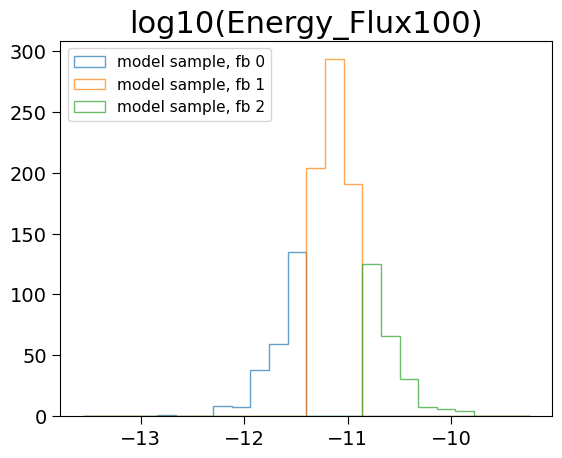

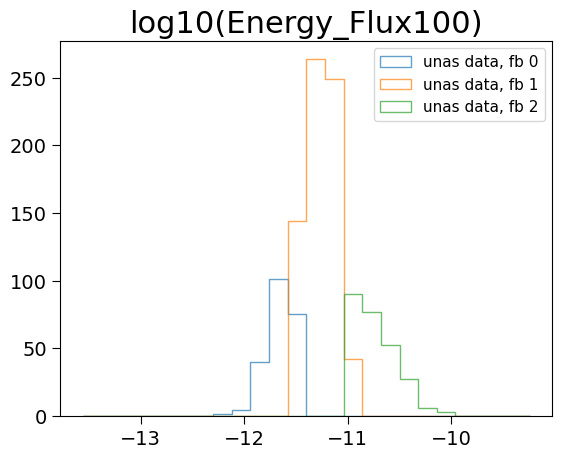

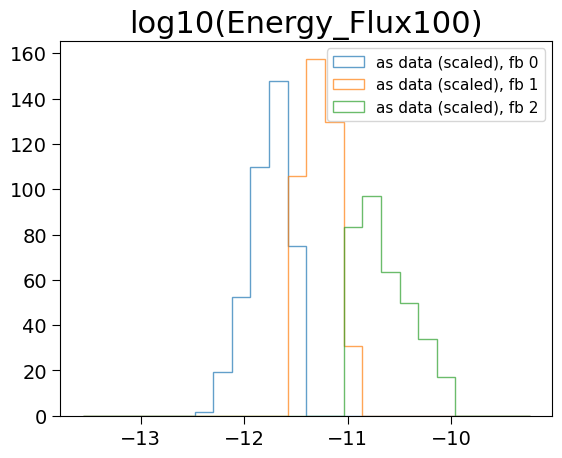

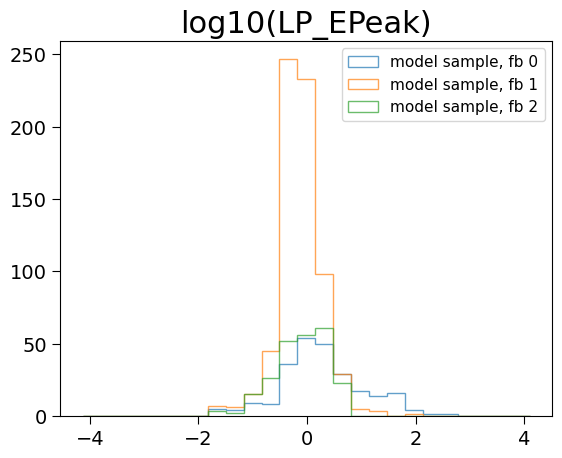

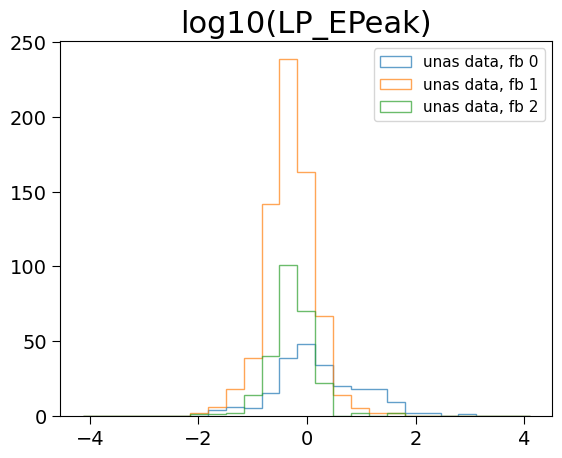

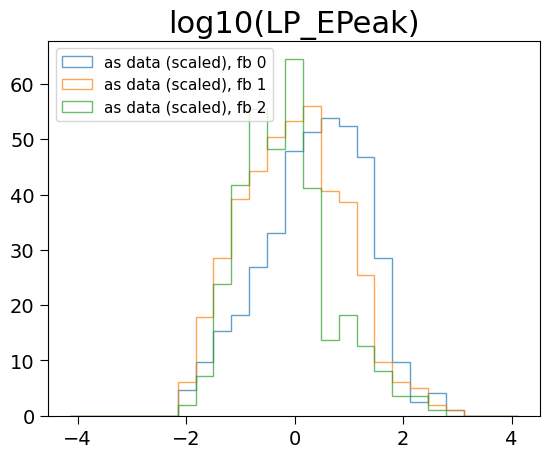

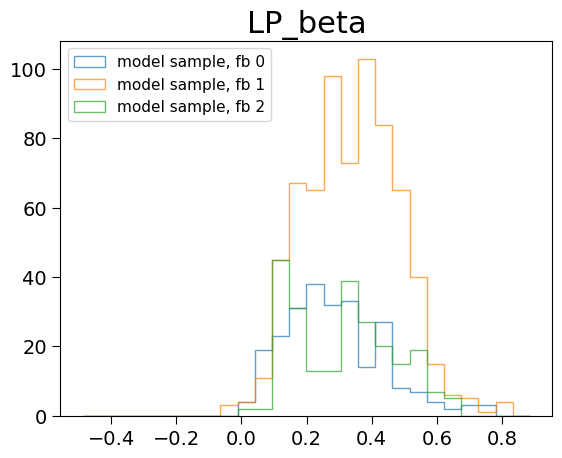

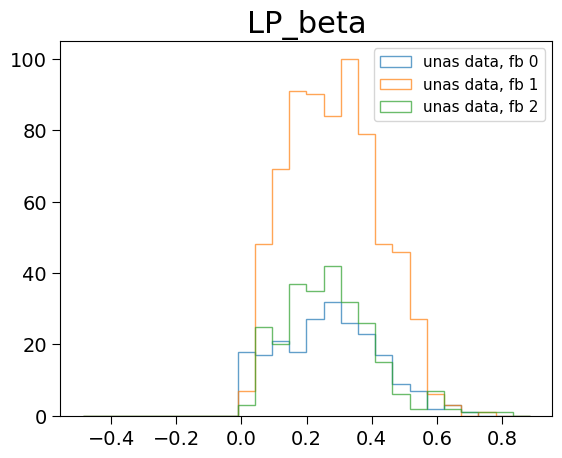

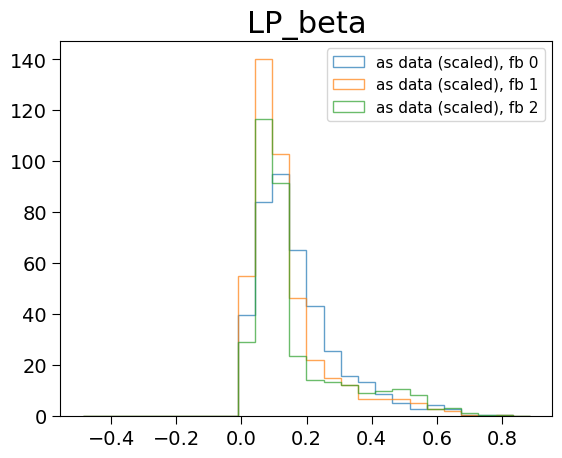

In [71]:
    
for k, feature in enumerate(features):
    pyplot.figure()
    ax = pyplot.subplot(1, 1, 1)
    for ind in range(len(fbins) - 1):
        fmin = fbins[ind]
        fmax = fbins[ind + 1]
        
        inorm = lambda x: inv_normalize_feature(x, mean_std_dict[bin_feature])
        smask = get_mask(inorm(xsample[:,fk]), fmin, fmax)
            
        inorm = lambda x: inv_normalize_feature(x, mean_std_dict[feature])
        pyplot.hist(inorm(xsample[smask,k]), bins=inorm(grids[k]), 
                    alpha=0.7, histtype='step', ls='-', label='model sample, fb %i' % ind)
        pyplot.title('%s' % (feature))
        pyplot.legend()
    pyplot.figure()
    ax = pyplot.subplot(1, 1, 1)
    for ind in range(len(fbins) - 1):
        fmin = fbins[ind]
        fmax = fbins[ind + 1]
        
        inorm = lambda x: inv_normalize_feature(x, mean_std_dict[bin_feature])
        umask = get_mask(inorm(xu_all[:,fk]), fmin, fmax)
            
        inorm = lambda x: inv_normalize_feature(x, mean_std_dict[feature])
        pyplot.hist(inorm(xu_all[umask,k]), bins=inorm(grids[k]), 
                    alpha=0.7, histtype='step', label='unas data, fb %i' % ind)
        pyplot.title('%s' % (feature))
        pyplot.legend()
    pyplot.figure()
    ax = pyplot.subplot(1, 1, 1)
    for ind in range(len(fbins) - 1):
        fmin = fbins[ind]
        fmax = fbins[ind + 1]
        
        inorm = lambda x: inv_normalize_feature(x, mean_std_dict[bin_feature])
        amask = get_mask(inorm(xa_all[:,fk]), fmin, fmax)
            
        inorm = lambda x: inv_normalize_feature(x, mean_std_dict[feature])
        pyplot.hist(inorm(xa_all[amask,k]), weights=weights[amask], bins=inorm(grids[k]), 
                    alpha=0.7, histtype='step', label='as data (scaled), fb %i' % ind)
        pyplot.title('%s' % (feature))
        pyplot.legend()

In [72]:
par_dict_GMM = {'model': 'GMM', 'GMM_pars':{'nGMM': 2}}
def get_PDF(par_dict=par_dict_GMM):
    if par_dict['model'] == 'GMM':
        nGMM = par_dict['GMM_pars']['nGMM']
        mdl = GaussianMixture(n_components=nGMM, init_params='random', n_init=3, random_state=3)
        def PDF(xs):
            mdl.fit(xs)
            pdf = lambda x: np.exp(mdl.score_samples(x))
            return pdf
        return PDF


In [73]:
nbins_fine = [101, 102, 103]
nsigma = 5
ranges_fine = [np.linspace(-nsigma, nsigma, nb) for nb in nbins_fine]
#bin_edge = np.linspace(-nsigma, nsigma, nbins+1)
#bin_centers = (bin_edge[1:] + bin_edge[:-1]) / 2
ranges_2D = ranges_fine[1:]
grid_2d0 = np.meshgrid(*ranges_2D, indexing='ij')
grid_2d = np.array([xx.flatten() for xx in grid_2d0]).T

save figure to file: ../plots/prior_shift/4FGL-DR4_GMM_PDF_no_coord_no_bcu_spp_pshift_nGauss1_npar4_sigmoid_npar4_unas_unk_unas_below_b10_nclass4_1Gauss//2D_distributions_assoc_4FGL-DR4_GMM_PDF_no_coord_no_bcu_spp_pshift_nGauss1_npar4_sigmoid_npar4_unas_unk_unas_below_b10_nclass4_1Gauss_log10(Energy_Flux100).pdf
save figure to file: ../plots/prior_shift/4FGL-DR4_GMM_PDF_no_coord_no_bcu_spp_pshift_nGauss1_npar4_sigmoid_npar4_unas_unk_unas_below_b10_nclass4_1Gauss//2D_distributions_assoc_4FGL-DR4_GMM_PDF_no_coord_no_bcu_spp_pshift_nGauss1_npar4_sigmoid_npar4_unas_unk_unas_below_b10_nclass4_1Gauss_log10(Energy_Flux100).png
save figure to file: ../plots/prior_shift/4FGL-DR4_GMM_PDF_no_coord_no_bcu_spp_pshift_nGauss1_npar4_sigmoid_npar4_unas_unk_unas_below_b10_nclass4_1Gauss//2D_distributions_fsrq_4FGL-DR4_GMM_PDF_no_coord_no_bcu_spp_pshift_nGauss1_npar4_sigmoid_npar4_unas_unk_unas_below_b10_nclass4_1Gauss_log10(Energy_Flux100).pdf
save figure to file: ../plots/prior_shift/4FGL-DR4_GMM_PDF_

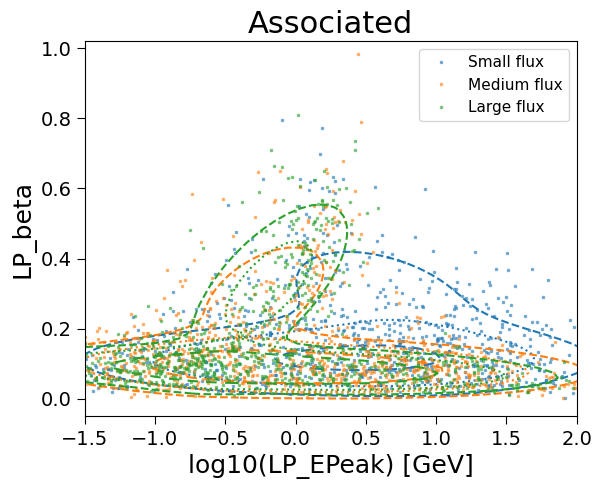

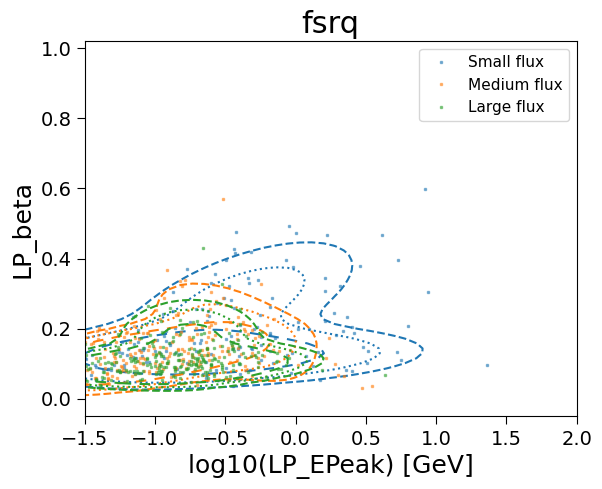

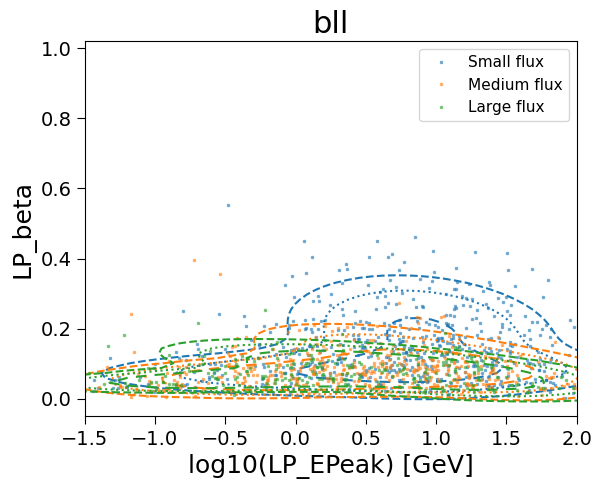

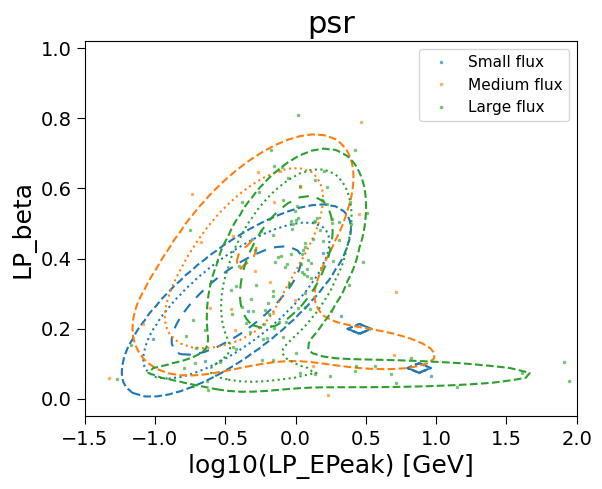

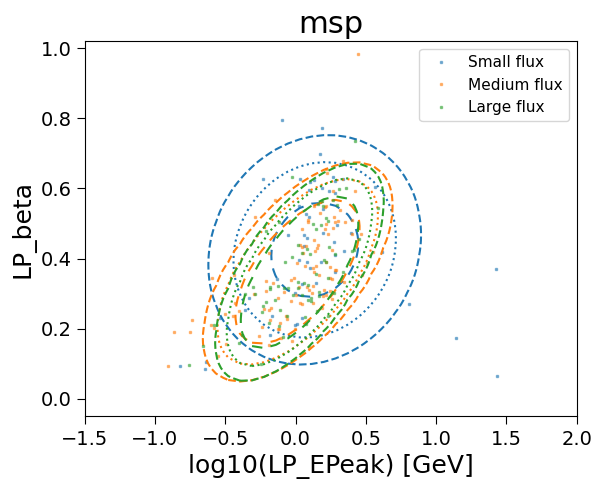

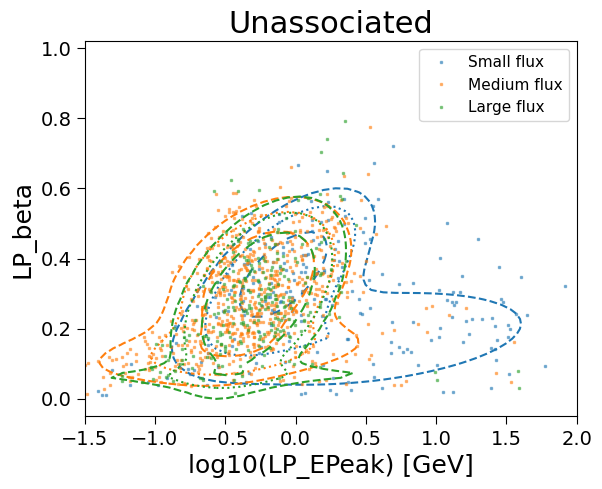

In [74]:
#lss = ['-', '--', '-.']
par_dict_GMM['GMM_pars']['nGMM'] = 2
alpha = 0.5
levels = [0.05, 0.1, 0.2,]
if nGaussians == 0:
    model_levels = levels
else:
    #model_levels = [0.01, 0.03, 0.05,]
    model_levels = [0.005, 0.01, 0.02,]

if 0:
    # old limits
    xmin = -0.2
    xmax = 1.02
    ymin = -3.5
    ymax = 3.5
else:
    # new limits to make ~ consistent with GU paper
    xmin = -1.5
    xmax = 2.
    ymin = -0.05
    ymax = 1.02
    
pyplot.figure()
ax = pyplot.subplot(1, 1, 1)
for ind in range(len(fbins) - 1):
    fmin = fbins[ind]
    fmax = fbins[ind + 1]

    inorm = lambda x: inv_normalize_feature(x, mean_std_dict[bin_feature])
    mask = get_mask(inorm(xa_all[:,fk]), fmin, fmax)

    inorm = lambda x: inv_normalize_feature(x, mean_std_dict[features[1]])
    f1 = inorm(xa_all[mask,1])
    ranges_2D_norm = [inorm(ranges_fine[1])]
    
    inorm = lambda x: inv_normalize_feature(x, mean_std_dict[features[2]])
    f2 = inorm(xa_all[mask,2])
    ranges_2D_norm.append(inorm(ranges_fine[2]))    
    grid_2d_norm = np.meshgrid(*ranges_2D_norm, indexing='ij')
    
    p = pyplot.plot(f1, f2, ls='', marker='s', ms=2, label=flabels[ind], alpha=alpha)
    color = p[0].get_color()
    pdf = get_PDF(par_dict=par_dict_GMM)(xa_all[mask,1:])
    pyplot.contour(ranges_2D_norm[0], ranges_2D_norm[1], 
                   pdf(grid_2d).reshape(nbins_fine[1], nbins_fine[2]).T, 
                   levels=levels, linestyles=lss, colors=color)
    #pyplot.imshow(pdf(grid_2d).reshape((nbins, nbins)), origin='lower', extent=extent, aspect='auto')
    #pyplot.colorbar()
    
    pyplot.xlabel(flabel_dict.get(features[1], features[1]))
    pyplot.ylabel(flabel_dict.get(features[2], features[2]))
    pyplot.legend()
    pyplot.title('Associated')

pyplot.xlim(xmin, xmax)
pyplot.ylim(ymin, ymax)
if save_plots:
    fn = '%s/2D_distributions_assoc_%s_%s.pdf' % (plots_folder, descr_str, bin_feature)
    print('save figure to file: %s' % (fn))
    pyplot.savefig(fn, metadata=fig_meta)
    if save_png:
        fn_png = fn.replace('.pdf', '.png')
        print('save figure to file: %s' % (fn_png))
        pyplot.savefig(fn_png, metadata=fig_meta)

for key in tree_cat_dict.keys():
    #print(key)
    cls = tree_cat_dict[key]
    clf_mask_dict[key] = util.get_cl_mask(cls, xdf, cname=class_name)
    xs = np.array(xdf[features][clf_mask_dict[key]])
    pyplot.figure()
    ax = pyplot.subplot(1, 1, 1)
    for ind in range(len(fbins) - 1):
        fmin = fbins[ind]
        fmax = fbins[ind + 1]

        inorm = lambda x: inv_normalize_feature(x, mean_std_dict[bin_feature])
        mask = get_mask(inorm(xs[:,fk]), fmin, fmax)

        inorm = lambda x: inv_normalize_feature(x, mean_std_dict[features[1]])
        f1 = inorm(xs[mask,1])
        inorm = lambda x: inv_normalize_feature(x, mean_std_dict[features[2]])
        f2 = inorm(xs[mask,2])

        p = pyplot.plot(f1, f2, ls='', marker='s', ms=2, label=flabels[ind], alpha=alpha)
        color = p[0].get_color()
        par_dict_GMM['GMM_pars']['nGMM'] = nGMM1_dict[key]
        pdf = get_PDF(par_dict=par_dict_GMM)(xs[mask,1:])
        pyplot.contour(ranges_2D_norm[0], ranges_2D_norm[1], 
                       pdf(grid_2d).reshape(nbins_fine[1], nbins_fine[2]).T, 
                       levels=levels, linestyles=lss, colors=color)
        #pyplot.imshow(pdf(grid_2d).reshape((nbins, nbins)), origin='lower', extent=extent, aspect='auto')
        #pyplot.colorbar()

        pyplot.xlabel(flabel_dict.get(features[1], features[1]))
        pyplot.ylabel(flabel_dict.get(features[2], features[2]))
        pyplot.legend()
        pyplot.title(class_dict.get(key, key))
    pyplot.xlim(xmin, xmax)
    pyplot.ylim(ymin, ymax)

    if save_plots:
        fn = '%s/2D_distributions_%s_%s_%s.pdf' % \
        (plots_folder, class_dict.get(key, key), descr_str, bin_feature)
        print('save figure to file: %s' % (fn))
        pyplot.savefig(fn, metadata=fig_meta)
        if save_png:
            fn_png = fn.replace('.pdf', '.png')
            print('save figure to file: %s' % (fn_png))
            pyplot.savefig(fn_png, metadata=fig_meta)

par_dict_GMM['GMM_pars']['nGMM'] = 2
pyplot.figure()
ax = pyplot.subplot(1, 1, 1)
for ind in range(len(fbins) - 1):
    fmin = fbins[ind]
    fmax = fbins[ind + 1]

    inorm = lambda x: inv_normalize_feature(x, mean_std_dict[bin_feature])
    mask = get_mask(inorm(xu_all[:,fk]), fmin, fmax)

    inorm = lambda x: inv_normalize_feature(x, mean_std_dict[features[1]])
    f1 = inorm(xu_all[mask,1])
    inorm = lambda x: inv_normalize_feature(x, mean_std_dict[features[2]])
    f2 = inorm(xu_all[mask,2])
    
    p = pyplot.plot(f1, f2, ls='', marker='s', ms=2, label=flabels[ind], alpha=alpha)
    color = p[0].get_color()
    pdf = get_PDF(par_dict=par_dict_GMM)(xu_all[mask,1:])
    pyplot.contour(ranges_2D_norm[0], ranges_2D_norm[1], 
                   pdf(grid_2d).reshape(nbins_fine[1], nbins_fine[2]).T, 
                   levels=levels, linestyles=lss, colors=color)

    pyplot.xlabel(flabel_dict.get(features[1], features[1]))
    pyplot.ylabel(flabel_dict.get(features[2], features[2]))
    pyplot.legend()
    pyplot.title('Unassociated')
pyplot.xlim(xmin, xmax)
pyplot.ylim(ymin, ymax)

if save_plots:
    fn = '%s/2D_distributions_unas_%s_%s.pdf' % (plots_folder, descr_str, bin_feature)
    print('save figure to file: %s' % (fn))
    pyplot.savefig(fn, metadata=fig_meta)
    if save_png:
        fn_png = fn.replace('.pdf', '.png')
        print('save figure to file: %s' % (fn_png))
        pyplot.savefig(fn_png, metadata=fig_meta)


In [75]:
[i for i in range(len(features))]

[0, 1, 2]

In [76]:
#ranges_fine = [[1,2],[3,4,5],[6,7,8,9]]
#xgrid_fine = np.meshgrid(*ranges_fine, indexing='ij')
#np.meshgrid?
#xgrid_fine[0].shape, len(xgrid_fine)

In [77]:
# PDF model on find grid

#grids = np.array(ranges_fine)
dx_fine = np.array([ranges_fine[i][1] - ranges_fine[i][0] for i in range(len(features))])
xgrid_fine = np.meshgrid(*ranges_fine, indexing='ij')
xgrid_fine = np.array([xx.flatten() for xx in xgrid_fine]).T
dV_fine = np.prod(dx_fine)
dS_fine = np.prod(dx_fine[1:])
PDF_fine = dV_fine * model(res_prior, res_cov,  **mdl_args)(xgrid_fine)
PDF_fine = PDF_fine.reshape(nbins_fine)
if nGaussians > 0:
    PDF_Gauss_fine = dV_fine * Gaussian_component(xgrid_fine, pars_fit_Gauss)
    PDF_Gauss_fine = PDF_Gauss_fine.reshape(nbins_fine)

In [78]:
ranges_2D_norm[0].shape, ranges_2D_norm[1].shape, pdf(grid_2d).reshape(nbins_fine[1::]).T.shape

((102,), (103,), (103, 102))

In [79]:
model_levels

[0.005, 0.01, 0.02]

In [80]:
xmin

-1.5

save figure to file: ../plots/prior_shift/4FGL-DR4_GMM_PDF_no_coord_no_bcu_spp_pshift_nGauss1_npar4_sigmoid_npar4_unas_unk_unas_below_b10_nclass4_1Gauss//prior_shift_2D_distributions_4FGL-DR4_GMM_PDF_no_coord_no_bcu_spp_pshift_nGauss1_npar4_sigmoid_npar4_unas_unk_unas_below_b10_nclass4_1Gauss_log10(Energy_Flux100)_fluxbin0.pdf
save figure to file: ../plots/prior_shift/4FGL-DR4_GMM_PDF_no_coord_no_bcu_spp_pshift_nGauss1_npar4_sigmoid_npar4_unas_unk_unas_below_b10_nclass4_1Gauss//prior_shift_2D_distributions_4FGL-DR4_GMM_PDF_no_coord_no_bcu_spp_pshift_nGauss1_npar4_sigmoid_npar4_unas_unk_unas_below_b10_nclass4_1Gauss_log10(Energy_Flux100)_fluxbin0.png
save figure to file: ../plots/prior_shift/4FGL-DR4_GMM_PDF_no_coord_no_bcu_spp_pshift_nGauss1_npar4_sigmoid_npar4_unas_unk_unas_below_b10_nclass4_1Gauss//prior_shift_2D_distributions_4FGL-DR4_GMM_PDF_no_coord_no_bcu_spp_pshift_nGauss1_npar4_sigmoid_npar4_unas_unk_unas_below_b10_nclass4_1Gauss_log10(Energy_Flux100)_fluxbin1.pdf
save figure t

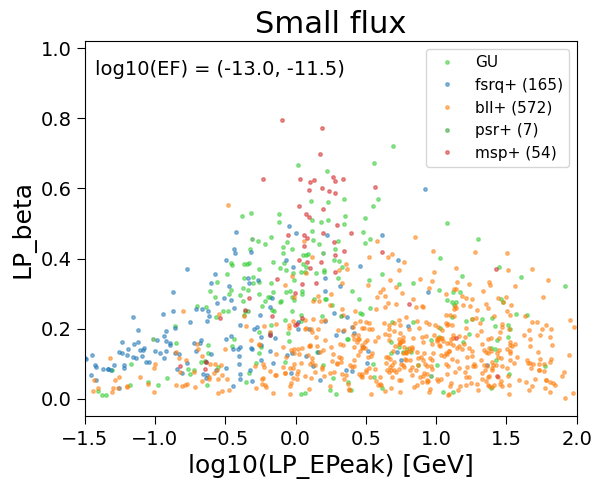

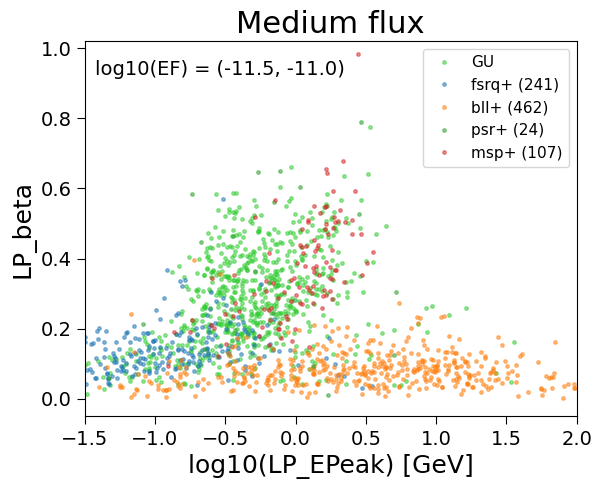

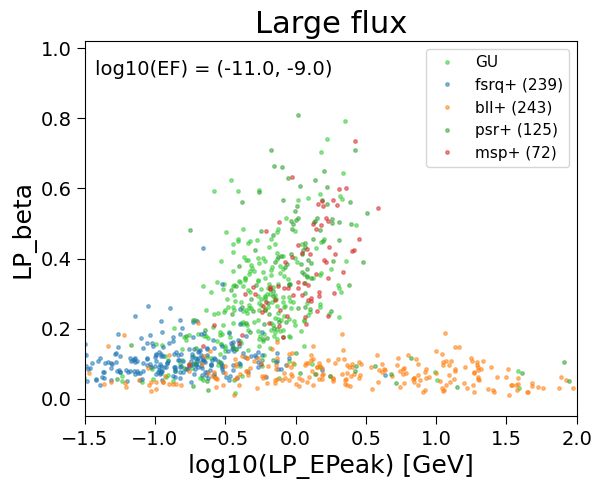

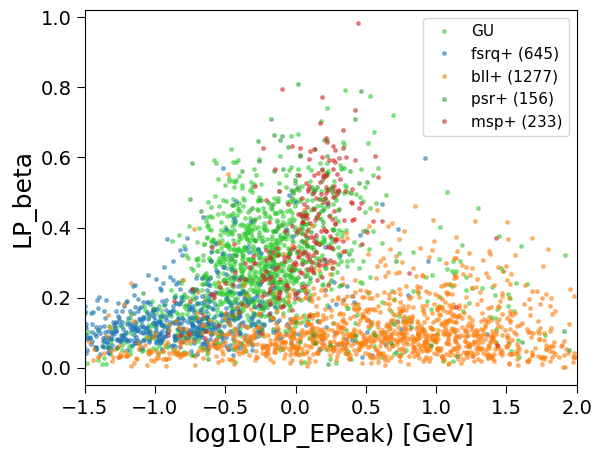

In [81]:
malpha = 0.6
ualpha = 0.8
ms = 2.5
marker = 'o'
show_models = 0
if show_models:
    mdl_str = '_mdl'
else:
    mdl_str = ''
    
shape_bins = nbins_fine[1::]
model_color = 'cyan'
for ind in range(len(fbins)):
    pyplot.figure()
    ax = pyplot.subplot(1, 1, 1)
    if ind == len(fbins) - 1:
        fmin = fbins[0]
        fmax = fbins[-1]
        par_dict_GMM['GMM_pars']['nGMM'] = 3
        #ms = 1.
    else:
        fmin = fbins[ind]
        fmax = fbins[ind + 1]
        par_dict_GMM['GMM_pars']['nGMM'] = 2
        #ms = 2
    

    inorm = lambda x: inv_normalize_feature(x, mean_std_dict[bin_feature])
    mask = get_mask(inorm(xu_all[:,fk]), fmin, fmax)

    inorm = lambda x: inv_normalize_feature(x, mean_std_dict[features[1]])
    f1 = inorm(xu_all[mask,1])
    inorm = lambda x: inv_normalize_feature(x, mean_std_dict[features[2]])
    f2 = inorm(xu_all[mask,2])
    
    color = mdl_style_dict['GU']['color']
    #label = 'Unas (%i)' % sum(mask)
    label = 'GU'
    
    p = pyplot.plot(f1, f2, ls='', marker=marker, ms=ms, color=color, alpha=alpha, label=label)
    if 0:
        #color = p[0].get_color()
        pdf = get_PDF(par_dict=par_dict_GMM)(xu_all[mask,1:])
        pyplot.contour(ranges_2D_norm[0], ranges_2D_norm[1], 
                       pdf(grid_2d).reshape(shape_bins).T, 
                       levels=levels, linestyles='--', colors=color, alpha=ualpha)
        #pyplot.plot([100, 101], [0, 1], ls='--', color=color, alpha=ualpha, label=label)

    
    for key in tree_cat_dict.keys():
        #print(key)
        cls = tree_cat_dict[key]
        clf_mask_dict[key] = util.get_cl_mask(cls, xdf, cname=class_name)
        xs = np.array(xdf[features][clf_mask_dict[key]])
        
        inorm = lambda x: inv_normalize_feature(x, mean_std_dict[bin_feature])
        mask = get_mask(inorm(xs[:,fk]), fmin, fmax)

        inorm = lambda x: inv_normalize_feature(x, mean_std_dict[features[1]])
        f1 = inorm(xs[mask,1])
        inorm = lambda x: inv_normalize_feature(x, mean_std_dict[features[2]])
        f2 = inorm(xs[mask,2])
        
        color = mdl_style_dict[key]['color']
        if class_dict[key] in ['Gauss', 'Extragalactic', 'Galactic']:
            #label = '%s (%i)' % (class_dict[key], sum(mask))
            label = '%s' % (class_dict[key])
        else:
            label = '%s+ (%i)' % (class_dict[key], sum(mask))

        p = pyplot.plot(f1, f2, ls='', marker=marker, ms=ms, color=color,
                        alpha=alpha, label=label)
        if show_models:
            if color is None:
                color = p[0].get_color()
            par_dict_GMM['GMM_pars']['nGMM'] = nGMM1_dict[key]
            pdf = get_PDF(par_dict=par_dict_GMM)(xs[mask,1:])

            pyplot.contour(ranges_2D_norm[0], ranges_2D_norm[1], 
                           pdf(grid_2d).reshape(shape_bins).T, 
                           levels=levels, linestyles='--', colors=color, alpha=malpha)
            pyplot.plot([100, 101], [0, 1], ls='--', color=color, alpha=malpha, label=label + ' mdl0')
            
    if show_models:
        #par_dict_GMM['GMM_pars']['nGMM'] = 2

        inorm = lambda x: inv_normalize_feature(x, mean_std_dict[bin_feature])
        grid_mask = get_mask(inorm(ranges_fine[0]), fmin, fmax)
        if nGaussians == 0:
            PDF_range = np.sum(PDF_fine[grid_mask,:,:], axis=0) * len(grid_mask) / sum(grid_mask)
            pyplot.contour(ranges_2D_norm[0], ranges_2D_norm[1], PDF_range.T / dS_fine, 
                           levels=model_levels, linestyles='--', colors=model_color, alpha=malpha)

            pyplot.plot([100, 101], [0, 1], ls='--', color=model_color, alpha=malpha, label='Model')
        else:
            if 0:
                PDF_range = np.sum((PDF_fine - PDF_Gauss_fine)[grid_mask,:,:], axis=0) * len(grid_mask) / sum(grid_mask)
                pyplot.contour(ranges_2D_norm[0], ranges_2D_norm[1], PDF_range.T / dS_fine, 
                               levels=model_levels, linestyles='--', colors=model_color, alpha=malpha)

                pyplot.plot([100, 101], [0, 1], ls='--', color=model_color, alpha=malpha, label='Model - Gauss')

            color = 'green' #mdl_style_dict['Gauss']['color']
            PDF_Gauss_range = np.sum(PDF_Gauss_fine[grid_mask,:,:], axis=0) * len(grid_mask) / sum(grid_mask)
            pyplot.contour(ranges_2D_norm[0], ranges_2D_norm[1], PDF_Gauss_range.T / dS_fine, 
                           levels=levels, linestyles='--', colors=color, alpha=ualpha)

            pyplot.plot([100, 101], [0, 1], ls='--', color=color, alpha=malpha, label='SGU-like (Gauss)')

    
    
    if ind < len(fbins) - 1:
        plot_textF = 'log10(EF) = (%.1f, %.1f)' % (fbins[ind], fbins[ind + 1])
        ax.text(0.02, 0.9, plot_textF, #fontsize=10, 
            transform=ax.transAxes,
            horizontalalignment='left', verticalalignment='bottom')


    pyplot.xlabel(flabel_dict.get(features[1], features[1]))
    pyplot.ylabel(flabel_dict.get(features[2], features[2]))
    pyplot.legend()
    if ind < 3:
        pyplot.title(flabels[ind])
    #xmin = ranges_2D_norm[0][0]
    #xmax = ranges_2D_norm[0][-1] + 0.2
    #ymin = ranges_2D_norm[1][0]
    #ymax = ranges_2D_norm[1][-1]
    pyplot.xlim(xmin, xmax)
    pyplot.ylim(ymin, ymax)
    
    if save_plots:
        fn = '%s/prior_shift_2D_distributions_%s_%s_fluxbin%i%s.pdf' % \
                (plots_folder, descr_str, bin_feature, ind, mdl_str)
        print('save figure to file: %s' % (fn))
        pyplot.savefig(fn, metadata=fig_meta)
        if save_png:
            fn_png = fn.replace('.pdf', '.png')
            print('save figure to file: %s' % (fn_png))
            pyplot.savefig(fn_png, metadata=fig_meta)


In [82]:
#pyplot.contour?

In [83]:
if 0:
    feature = 'log10(LP_EPeak)'
    pyplot.figure()
    ax = pyplot.subplot(1, 1, 1)
    pyplot.hist(logEpeak_sample, bins=bins_epeak, alpha=0.5, label='model sample')
    pyplot.hist(logEpeak_unas, bins=bins_epeak, alpha=0.5, label='unas data')
    #if feature_mode.find('Toby') > -1:
    #    pyplot.hist(logEpeak_unas_check, bins=bins, alpha=0.5, label='unas data check')
    pyplot.hist(logEpeak_assoc, weights=weights, bins=bins_epeak, histtype='step', alpha=1, label='assoc data (scaled)')
    #pyplot.xlabel(feature)
    pyplot.xlabel(flabel_dict.get(feature, feature))

    pyplot.legend()
    ax.text(0.98, 0.7, plot_textF, #fontsize=10, 
            transform=ax.transAxes,
            horizontalalignment='right', verticalalignment='bottom')

    if save_plots and ('log10Epeak' not in features):
        fn = '%s/prior_shift_model_%s_%s.pdf' % (plots_folder, descr_str, feature)
        print('save figure to file: %s' % (fn))
        pyplot.savefig(fn, metadata=fig_meta)
        if save_png:
            fn_png = fn.replace('.pdf', '.png')
            print('save figure to file: %s' % (fn_png))
            pyplot.savefig(fn_png, metadata=fig_meta)


In [84]:
xa_all.shape

(2311, 3)

In [85]:
logEpeak_sample.shape

(1175,)

In [86]:
xdf.columns

Index(['sin(GLAT)', 'cos(GLON)', 'sin(GLON)', 'log10(Energy_Flux100)',
       'log10(Unc_Energy_Flux100)', 'log10(Signif_Avg)', 'LP_index1000MeV',
       'LP_beta', 'LP_SigCurv', 'log10(Variability_Index)', 'CLASS1', 'GLON',
       'GLAT', 'Signif_Avg', 'log10(LP_EPeak)', 'Pivot_Energy'],
      dtype='object')

In [87]:
if ng_pars > 0:
    ng_src = len(xu_all) * np.exp(pars_fit_Gauss[0])
    print('Expected number of Gauss SGU-like sources: %.3f (%.1f per cent of all)' % (ng_src, 100*ng_src/len(xu_all)))


Expected number of Gauss SGU-like sources: 572.906 (48.8 per cent of all)


In [88]:
mus = pars_fit_Gauss[1::2]
sigmas = pars_fit_Gauss[2::2]
print('Features')
print(features)
print('Unnormalized')
print('Means', mus)
print('Sigmas', sigmas)

Features
['log10(Energy_Flux100)', 'log10(LP_EPeak)', 'LP_beta']
Unnormalized
Means [ 0.38887369 -0.37470957  0.65403309]
Sigmas [0.49797313 0.28403011 0.77288665]


In [89]:
print('Distribution of')
for k, feature in enumerate(features):
    # inverse norm function
    dct = mean_std_dict[feature]
    mu = mus[k] * dct['std'] + dct['mean']
    sigma = sigmas[k] * dct['std']
    print('%s: %.2f +- %.2f' % (feature, mu, sigma))

Distribution of
log10(Energy_Flux100): -11.23 +- 0.22
log10(LP_EPeak): -0.33 +- 0.24
LP_beta: 0.29 +- 0.11


In [90]:
npar

4

In [91]:
print('total number of unassociated sources (inside the mask): %i' % np.sum(unas_mask))

total number of unassociated sources (inside the mask): 1175


In [92]:
len(xu_all)

1175